# SiO₂ Melt Curve Fits

We use a 3 part fit to generate a fiducial model melt curve from 14 to 6000 GPa. 

15-55 GPa: Fit to static lab data; rms=154 K<br>
55-513 GPa: Using 2-phase melt curve equation from Geng and Mohn 2024; 1-sigma~200 K<br>
513-6000 GPa: Fit to modified Gonzalez et al. 2016 (used Z method to determine melt curve); rms=207 K<p>

An estimate of the melt curve temperature fit uncertainty is 1σ = ±250 K.
Systematic uncertainties related to PBE DFT and static DAC measurements may be greater.

The Gonzalez MC overlapping point with MC24 was shifted upward by about 130 K to intersect the GM2024 melt curve. This is within the error of the melt curves.

Updated 10/21/2026 sts

In [2]:
%%capture 
## This cell loads the modules, data, and EOS parameters
## capture magic function hides the output; comment out to see diagnostic info during data load
## Run executable notebook for output

%run -i scripts/set_paths
%run -i scripts/load_modules
%run -i scripts/load_silica_data
%run -i scripts/define_mc
%run -i scripts/define_eos
%run -i scripts/calibrate_decaying_shocks.py
%run -i scripts/load_vapor_domes.py
%run -i scripts/load_liquid_model.py
%run -i scripts/load_solid_models.py
#%run -i scripts/hugoniot-calcs.py
%run -i scripts/intersection.py # intersection function
%run -i scripts/odr_models.py # ODR and model functions # REMOVE 
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors

# this notebook's figure name tag
tag = 'MCF-'
stsmcsmoothorig = deepcopy(stsmcsmooth)



## Gonzales et al. 2016 - no tweak

Only fitting points beyond the Geng and Mohn 2024 paper.

The Simons curve fit to this data does not intersect the Geng and Mohn recommended 2-phase fit melt curve.


FIT EOS a =  [-6.36275124e+03  3.34236196e+03  2.41679030e-01]
FIT EOS cov =  [[ 2.33434318e+06 -1.10998143e+06  2.87367104e+01]
 [-1.10998143e+06  5.29326870e+05 -1.37257017e+01]
 [ 2.87367104e+01 -1.37257017e+01  3.56257994e-04]]
Saved EOS fit in SiO2_fitG16_simons.txt
Saved EOS fit in readable file SiO2_fitG16_simons-readable.txt
rms =  223.5249848435821


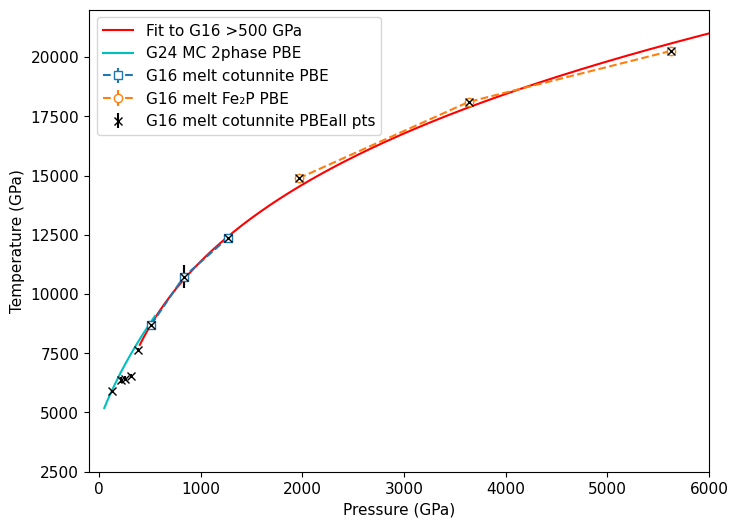

No intersection:  [] []


In [3]:
plt.errorbar(eosdat_list[G16mc['id']].P[5:8],eosdat_list[G16mc['id']].T[5:8],fmt='s--',mfc='white',yerr=eosdat_list[G16mc['id']].T_std[5:8],label=G16mcb['lab']) # cotunnite structure
plt.errorbar(eosdat_list[G16mc['id']].P[8:11],eosdat_list[G16mc['id']].T[8:11],fmt='o--',mfc='white',yerr=eosdat_list[G16mc['id']].T_std[8:11],label=G16mcc['lab']) # Fe2P structure

plt.errorbar(eosdat_list[G16mc['id']].P[::],eosdat_list[G16mc['id']].T[::],fmt='kx',yerr=eosdat_list[G16mc['id']].T_std[::],label=G16mcb['lab']+'all pts')

fitx = eosdat_list[G16mc['id']].P[5:11]
fitf= eosdat_list[G16mc['id']].T[5:11]
fitx_std = eosdat_list[G16mc['id']].P[5:11]*.01
fitf_std = eosdat_list[G16mc['id']].T_std[5:11]
fitrefid = np.full(len(fitx), eosdat_list[G16mc['id']].refidlist[1], dtype=int)
fitreflist=[]
for i in np.unique(fitrefid):
    fitreflist.append(str(i)+': '+ref_list[i].reference[0])

# initialize the HPeos_Fit class
sio2_mc_G16 = hp.HPeos_Fit()
sio2_mc_G16.formula = 'SiO2'
sio2_mc_G16.x = fitx
sio2_mc_G16.f = fitf
sio2_mc_G16.x_std = fitx_std
sio2_mc_G16.f_std = fitf_std
sio2_mc_G16.refid = fitrefid
sio2_mc_G16.reflist = fitreflist
sio2_mc_G16.x_var = 'P'
sio2_mc_G16.f_var = 'T'
sio2_mc_G16.x_units = 'GPa'
sio2_mc_G16.f_units = 'K'
sio2_mc_G16.x_desc = 'Pressure'
sio2_mc_G16.f_desc = 'Temperature'
sio2_mc_G16.phase_fit = 'melt curve'
DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
sio2_mc_G16.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]

sio2_mc_G16.curvetype = 'simons'
sio2_mc_G16.outputfitpath = outputfitpath # in load_paths.py
sio2_mc_G16.filename = 'SiO2_fitG16_simons'
sio2_mc_G16.a0 = np.asarray([2000,300,.2])
sio2_mc_G16.fit()
print('FIT EOS a = ',sio2_mc_G16.a)
print('FIT EOS cov = ',sio2_mc_G16.cov)
sio2_mc_G16.savejson()
sio2_mc_G16.savereadable()
print('rms = ',sio2_mc_G16.rms)
#plt.errorbar(fitx,fitf,xerr=fitx_std,yerr=fitf_std,fmt='x',label='fitted points')

P_var = np.arange(400,6000,1)
T_var = sio2_mc_G16.calcf(P_var)

plt.plot(P_var,T_var,'r-',label='Fit to G16 >500 GPa')
#plt.plot(stsmcsmooth.P,stsmcsmooth.T,'m-',linewidth=3)


plt.plot(gm24mc.P,gm24mc.T,'-',color='c',label='G24 MC 2phase PBE')


plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (GPa)')
plt.xlim(-100,6000)
plt.ylim(2500,22000)
#plt.xlim(0,600)
#plt.ylim(2500,10000)
plt.legend()
plt.show()

x,y=intersection(gm24mc.P,gm24mc.T,P_var,T_var)
print('No intersection: ',x,y)

## Gonzales et al. 2016 - tweak to intersect GM24

Shift the lowest pressure point to fall on the GM24 melt curve.


Original temperature =  8702.972
Modified temperature =  8835.963323826292
FIT EOS a =  [-5.89112815e+03  3.22036386e+03  2.43745258e-01]
FIT EOS cov =  [[ 2.24243236e+06 -1.05537438e+06  2.84290722e+01]
 [-1.05537438e+06  4.98144932e+05 -1.34400139e+01]
 [ 2.84290722e+01 -1.34400139e+01  3.62961481e-04]]
Saved EOS fit in SiO2_fitG16mod_simons.txt
Saved EOS fit in readable file SiO2_fitG16mod_simons-readable.txt
rms =  207.65082999888475


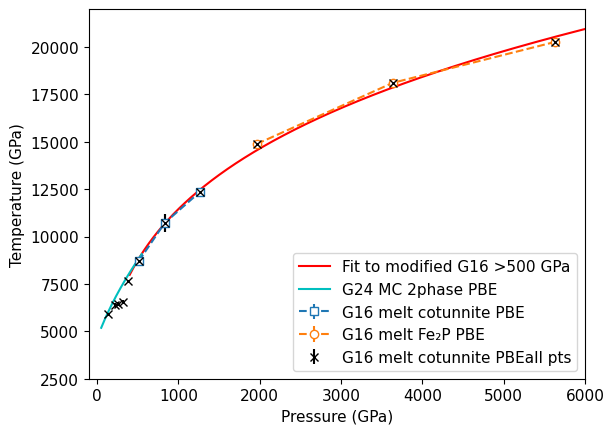

Intersection:  [512.83694338] [8847.2443504]


In [4]:
plt.errorbar(eosdat_list[G16mc['id']].P[5:8],eosdat_list[G16mc['id']].T[5:8],fmt='s--',mfc='white',yerr=eosdat_list[G16mc['id']].T_std[5:8],label=G16mcb['lab']) # cotunnite structure
plt.errorbar(eosdat_list[G16mc['id']].P[8:11],eosdat_list[G16mc['id']].T[8:11],fmt='o--',mfc='white',yerr=eosdat_list[G16mc['id']].T_std[8:11],label=G16mcc['lab']) # Fe2P structure

plt.errorbar(eosdat_list[G16mc['id']].P[::],eosdat_list[G16mc['id']].T[::],fmt='kx',yerr=eosdat_list[G16mc['id']].T_std[::],label=G16mcb['lab']+'all pts')

fitx = np.copy(eosdat_list[G16mc['id']].P[5:11])
fitf= np.copy(eosdat_list[G16mc['id']].T[5:11])
print('Original temperature = ',fitf[0])
fitf[0] = np.interp(fitx[0],gm24mc.P,gm24mc.T) # modify G16 lowest point to match GM24 melt curve
print('Modified temperature = ',fitf[0])
fitx_std = eosdat_list[G16mc['id']].P[5:11]*.01
fitf_std = eosdat_list[G16mc['id']].T_std[5:11]
fitrefid = np.full(len(fitx), eosdat_list[G16mc['id']].refidlist[1], dtype=int)
fitreflist=[]
for i in np.unique(fitrefid):
    fitreflist.append(str(i)+': '+ref_list[i].reference[0])

# initialize the HPeos_Fit class
sio2_mc_G16mod = hp.HPeos_Fit()
sio2_mc_G16mod.formula = 'SiO2'
sio2_mc_G16mod.x = fitx
sio2_mc_G16mod.f = fitf
sio2_mc_G16mod.x_std = fitx_std
sio2_mc_G16mod.f_std = fitf_std
sio2_mc_G16mod.refid = fitrefid
sio2_mc_G16mod.reflist = fitreflist
sio2_mc_G16mod.x_var = 'P'
sio2_mc_G16mod.f_var = 'T'
sio2_mc_G16mod.x_units = 'GPa'
sio2_mc_G16mod.f_units = 'K'
sio2_mc_G16mod.x_desc = 'Pressure'
sio2_mc_G16mod.f_desc = 'Temperature'
sio2_mc_G16mod.phase_fit = 'melt curve'
DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
sio2_mc_G16mod.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit modified lowest pressure point to intersect Geng & Mohn 2024']]

sio2_mc_G16mod.curvetype = 'simons'
sio2_mc_G16mod.outputfitpath = outputfitpath # in load_paths.py
sio2_mc_G16mod.filename = 'SiO2_fitG16mod_simons'
sio2_mc_G16mod.a0 = np.asarray([2000,300,.2])
sio2_mc_G16mod.fit()
print('FIT EOS a = ',sio2_mc_G16mod.a)
print('FIT EOS cov = ',sio2_mc_G16mod.cov)
sio2_mc_G16mod.savejson()
sio2_mc_G16mod.savereadable()
print('rms = ',sio2_mc_G16mod.rms)
#plt.errorbar(fitx,fitf,xerr=fitx_std,yerr=fitf_std,fmt='x',label='fitted points')

P_var = np.arange(400,6000,1)
T_var = sio2_mc_G16mod.calcf(P_var)

plt.plot(P_var,T_var,'r-',label='Fit to modified G16 >500 GPa')

plt.plot(gm24mc.P,gm24mc.T,'-',color='c',label='G24 MC 2phase PBE')


plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (GPa)')
plt.xlim(-100,6000)
plt.ylim(2500,22000)
#plt.xlim(0,600)
#plt.ylim(2500,10000)
plt.legend()
plt.show()

x,y=intersection(gm24mc.P,gm24mc.T,P_var,T_var)
print('Intersection: ',x,y)

Intersection point (P,T)= 512.8369433815569 8847.244350397474


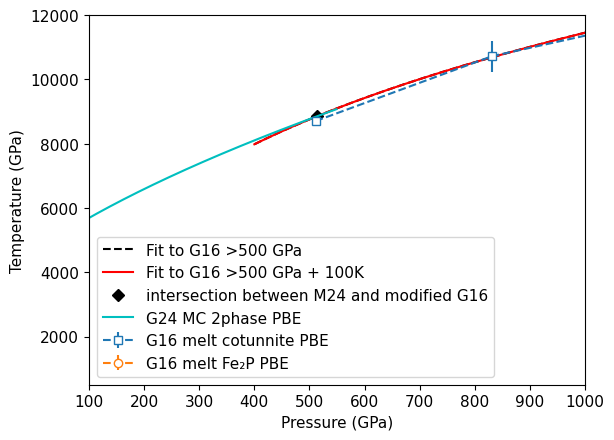

In [5]:


plt.plot(P_var,T_var,'k--',label='Fit to G16 >500 GPa')
plt.plot(P_var,T_var,'r-',label='Fit to G16 >500 GPa + 100K')
x,y=intersection(gm24mc.P,gm24mc.T,P_var,T_var)
p2=x[0]
t2=y[0]
plt.plot(p2,t2,'kD',label='intersection between M24 and modified G16')
print('Intersection point (P,T)=',p2,t2)
#plt.plot(stsmcsmooth.P,stsmcsmooth.T,'m-',linewidth=3)

plt.plot(gm24mc.P,gm24mc.T,'-',color='c',label='G24 MC 2phase PBE')

plt.errorbar(eosdat_list[G16mc['id']].P[5:8],eosdat_list[G16mc['id']].T[5:8],fmt='s--',mfc='white',yerr=eosdat_list[G16mc['id']].T_std[5:8],label=G16mcb['lab']) # cotunnite structure
plt.errorbar(eosdat_list[G16mc['id']].P[8:11],eosdat_list[G16mc['id']].T[8:11],fmt='o--',mfc='white',yerr=eosdat_list[G16mc['id']].T_std[8:11],label=G16mcc['lab']) # Fe2P structure

plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (GPa)')
plt.xlim(100,1000)
plt.ylim(500,12000)

plt.legend()
plt.show()

## Stishovite low-pressure region melt curve

Fit Simons equation to static lab experiments for melt curve.

[ 13.7    5.26   8.6   14.9   15.5   20.5   23.7   24.    29.    34.
  14.    25.    28.    36.    37.    37.    38.    40.    42.    46.
  55.    60.    66.    74.   102.   101.   114.   117.  ] [3073. 2750. 2900. 3400. 3450. 3900. 4100. 3950. 4100. 4250. 2816. 3877.
 3836. 4401. 4751. 4713. 4558. 4866. 4942. 4866. 4866. 5018. 5093. 5018.
 5605. 5533. 5957. 6163.] [ 50. 100.  70. 130. 120. 150. 180. 180. 280. 200. 250. 250. 250. 250.
 250. 250. 250. 250. 250. 250. 250. 250. 250. 250. 250. 250. 250. 250.]
[ 13.7  14.9  15.5  20.5  23.7  24.   29.   34.   14.   25.   28.   36.
  37.   37.   38.   40.   42.   46.   55.   60.   66.   74.  102.  101.
 114.  117. ] [3073. 3400. 3450. 3900. 4100. 3950. 4100. 4250. 2816. 3877. 3836. 4401.
 4751. 4713. 4558. 4866. 4942. 4866. 4866. 5018. 5093. 5018. 5605. 5533.
 5957. 6163.]
FIT EOS a =  [-1.47702719e+04  1.51139468e+04  6.65902384e-02]
FIT EOS cov =  [[ 1.61765257e+09 -1.58009812e+09  5.62103657e+03]
 [-1.58009812e+09  1.54344277e+09 -5.49104

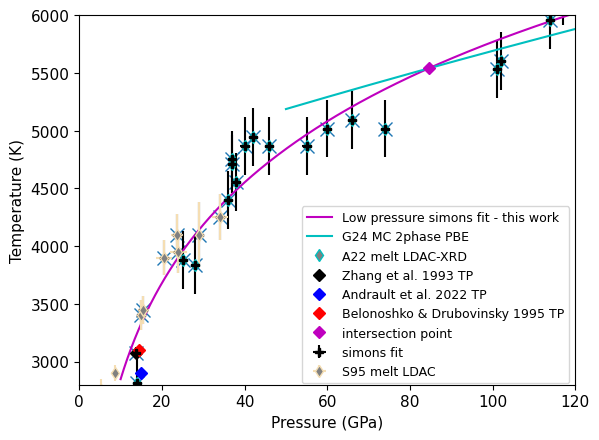

In [6]:

pvar = np.concatenate(([13.7],eosdat_list[S95mcstv['id']].P,eosdat_list[A22mc['id']].P))
tvar = np.concatenate(([3073],eosdat_list[S95mcstv['id']].T,eosdat_list[A22mc['id']].T))
tstd = np.concatenate(([50],eosdat_list[S95mcstv['id']].T_std,eosdat_list[A22mc['id']].T_std)) # Zhang et al. report 50C uncertainty in this range
#ind = np.where((pvar>13.6) & (pvar < 126) & (tvar>3000))
#ind = np.where((pvar>13.6) & (pvar < 50) & (tvar>3000))
ind = np.where((pvar>10) & (pvar < 126))
#ind = np.where((pvar>14) & (pvar < 50))

print(pvar,tvar,tstd)
print(pvar[ind],tvar[ind])
plt.plot(pvar[ind],tvar[ind],'x',markersize=10)

if 1:
    # fit lab data for STV steep slope melt curve
    
    fitx = pvar[ind]
    fitf = tvar[ind]
    fitx_std = np.zeros(len(fitx))+1
    fitf_std = tstd[ind]
#    fitrefid = np.full(len(fitx), -99, dtype=int)
#    fitreflist=[]
#    for i in np.unique(fitrefid):
#        fitreflist.append(str(i)+': misc')

    # per-point source ids, in the same order as pvar = [Zhang TP, S95 points, A22 points]
    refZ93 = -1                                              # Zhang et al. 1993 (not in reference database)
    refS95 = eosdat_list[S95mcstv['id']].refidlist[1]
    refA22 = eosdat_list[A22mc['id']].refidlist[1]
    refall = np.concatenate(([refZ93],
                             np.full(len(eosdat_list[S95mcstv['id']].P), refS95, dtype=int),
                             np.full(len(eosdat_list[A22mc['id']].P), refA22, dtype=int)))
    fitrefid = refall[ind]
    fitreflist = []
    for i in np.unique(fitrefid):
        if i == refZ93:
            fitreflist.append(str(i)+': Zhang, J., Liebermann, R. C., Gasparik, T., Herzberg, C. T., & Fei, Y. '
                              '(1993). Melting and subsolidus relations of SiO2 at 9-14 GPa. Journal of '
                              'Geophysical Research: Solid Earth, 98(B11), 19785-19793. '
                              'https://doi.org/10.1029/93JB02218 (coesite-stishovite-liquid triple point)')
        else:
            fitreflist.append(str(i)+': '+ref_list[i].reference[0])

    
    # initialize the HPeos_Fit class
    sio2_mc_static = hp.HPeos_Fit()
    sio2_mc_static.formula = 'SiO2'
    sio2_mc_static.x = fitx
    sio2_mc_static.f = fitf
    sio2_mc_static.x_std = fitx_std
    sio2_mc_static.f_std = fitf_std
    sio2_mc_static.refid = fitrefid
    sio2_mc_static.reflist = fitreflist
    sio2_mc_static.x_var = 'P'
    sio2_mc_static.f_var = 'T'
    sio2_mc_static.x_units = 'GPa'
    sio2_mc_static.f_units = 'K'
    sio2_mc_static.x_desc = 'Pressure'
    sio2_mc_static.f_desc = 'Temperature'
    sio2_mc_static.phase_fit = 'melt curve'
    DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
    sio2_mc_static.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]
    
    sio2_mc_static.curvetype = 'simons'
#    sio2_mc_static.curvetype = 'cubic'
    sio2_mc_static.outputfitpath = outputfitpath # in load_paths.py
    sio2_mc_static.filename = 'SiO2_fitstvstatic_simons'
#    sio2_mc_static.filename = 'SiO2_fitstvstatic_cubic'
    sio2_mc_static.a0 = np.asarray([3000,300,.2])


    sio2_mc_static.remlist.append('Fit to static melting data on the stishovite/CaCl2-type melt curve, '
        '10 < P < 126 GPa: Zhang et al. (1993) triple point (13.7 GPa, 3073 K, 50 K uncertainty; refid -1), '
        'laser-heated DAC data of Shen & Lazor (1995) and Andrault et al. (2022).')
    sio2_mc_static.remlist.append('Pressure uncertainty set to 1 GPa for all points.')

    sio2_mc_static.fit()
    print('FIT EOS a = ',sio2_mc_static.a)
    print('FIT EOS cov = ',sio2_mc_static.cov)
    sio2_mc_static.savejson()
    sio2_mc_static.savereadable()
    print('rms = ',sio2_mc_static.rms)
    plt.errorbar(fitx,fitf,xerr=fitx_std,yerr=fitf_std,fmt='kP',label='simons fit')

sio2_mc_stv = deepcopy(sio2_mc_static)
#    '''Simons function f(x) = a[0] + a[1]*x^a[2]'''
ppp = np.arange(10,120,.1)
ttt = sio2_mc_static.calcf(ppp)#sio2_mc_static.a[0]+sio2_mc_static.a[1]*np.pow(ppp,sio2_mc_static.a[2])
plt.plot(ppp,ttt,'m-',label='Low pressure simons fit - this work')
plt.plot(gm24mc.P,gm24mc.T,'-',color='c',label='G24 MC 2phase PBE')
ppp1 = ppp
ttt1 = ttt

if 1:
    # DAC melt curve points
    # stv melt curve Shen and Lazer 1995
    plt.errorbar(eosdat_list[S95mcstv['id']].P,eosdat_list[S95mcstv['id']].T,\
                 xerr=eosdat_list[S95mcstv['id']].P_std,yerr=eosdat_list[S95mcstv['id']].T_std,\
                 fmt='d',color='wheat',mfc='grey',label=S95mcstv['lab'])
    # Andrault et al. 2022 revised
    plt.plot(eosdat_list[A22mc['id']].P,eosdat_list[A22mc['id']].T,'cd',mfc='grey',label=A22mc['lab'])
    plt.plot(13.7,2800+273,'kD',label='Zhang et al. 1993 TP')
    plt.plot(15,2900,'bD',label='Andrault et al. 2022 TP')
    plt.plot(14.5,3100,'rD',label='Belonoshko & Drubovinsky 1995 TP')

if 1:
    x1,y1=intersection(gm24mc.P,gm24mc.T,ppp,ttt)
    p1=x1[0]
    t1=y1[0]
    print('Intersection (P,T) = ',p1,t1)
    plt.plot(p1,t1,'mD',label='intersection point')


plt.xlim(0,120)
plt.ylim(2800,6000)
plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')

plt.legend(bbox_to_anchor=(1, 0.5),fontsize=lfss)
plt.show()

In [7]:
plt.plot(eosdat_list[G14mc['id']].P,eosdat_list[G14mc['id']].T,color="black")#,label='Low-P Phases')

ind = np.where( (eosdat_list[G14mc['id']].P>4.25) & (eosdat_list[G14mc['id']].P < 14))[0]

if 1:
    # fit lab data for STV steep slope melt curve
    
    fitx = eosdat_list[G14mc['id']].P[ind]
    fitf = eosdat_list[G14mc['id']].T[ind]
    fitx_std = np.zeros(len(fitx))+1
    fitf_std = np.zeros(len(fitx))+10
    fitrefid = np.full(len(fitx), -99, dtype=int)
    fitreflist=[]
    for i in np.unique(fitrefid):
        fitreflist.append(str(i)+': misc')
    
    # initialize the HPeos_Fit class
    sio2_mc_staticlow = hp.HPeos_Fit()
    sio2_mc_staticlow.formula = 'SiO2'
    sio2_mc_staticlow.x = fitx
    sio2_mc_staticlow.f = fitf
    sio2_mc_staticlow.x_std = fitx_std
    sio2_mc_staticlow.f_std = fitf_std
    sio2_mc_staticlow.refid = fitrefid
    sio2_mc_staticlow.reflist = fitreflist
    sio2_mc_staticlow.x_var = 'P'
    sio2_mc_staticlow.f_var = 'T'
    sio2_mc_staticlow.x_units = 'GPa'
    sio2_mc_staticlow.f_units = 'K'
    sio2_mc_staticlow.x_desc = 'Pressure'
    sio2_mc_staticlow.f_desc = 'Temperature'
    sio2_mc_staticlow.phase_fit = 'melt curve'
    DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
    sio2_mc_staticlow.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]
    
    sio2_mc_staticlow.curvetype = 'cubic'
    sio2_mc_staticlow.outputfitpath = outputfitpath # in load_paths.py
    sio2_mc_staticlow.filename = 'SiO2_fitcoesitestatic_simons'
    sio2_mc_staticlow.a0 = np.asarray([3000,300,.2])
    sio2_mc_staticlow.fit()
    print('FIT EOS a = ',sio2_mc_staticlow.a)
    print('FIT EOS cov = ',sio2_mc_staticlow.cov)
    sio2_mc_staticlow.savejson()
    sio2_mc_staticlow.savereadable()
    print('rms = ',sio2_mc_staticlow.rms)
    plt.errorbar(fitx,fitf,fmt='kP',label='simons fit')

sio2_mc_cst = deepcopy(sio2_mc_staticlow)
#    '''Simons function f(x) = a[0] + a[1]*x^a[2]'''
ppp = np.arange(.5,15,.1)
ttt = sio2_mc_staticlow.calcf(ppp)
plt.plot(ppp,ttt,'m-',label='Lowest pressure simons fit - this work')
#plt.plot(gm24mc.P,gm24mc.T,'-',color='c',label='G24 MC 2phase PBE')
ppp0 = ppp
ttt0 = ttt
pppcst = ppp
tttcst = ttt

print(pppcst,tttcst)

FIT EOS a =  [ 2.05755695e+03  2.09541967e+02 -1.76612883e+01  5.10819398e-01]
FIT EOS cov =  [[ 3.27387105e+04 -1.02783758e+04  1.03715928e+03 -3.38633633e+01]
 [-1.02783758e+04  3.28489604e+03 -3.36183825e+02  1.11041058e+01]
 [ 1.03715928e+03 -3.36183825e+02  3.48100577e+01 -1.16120171e+00]
 [-3.38633633e+01  1.11041058e+01 -1.16120171e+00  3.90711413e-02]]
Saved EOS fit in SiO2_fitcoesitestatic_simons.txt
Saved EOS fit in readable file SiO2_fitcoesitestatic_simons-readable.txt
rms =  3.140574969864312
[ 0.5  0.6  0.7  0.8  0.9  1.   1.1  1.2  1.3  1.4  1.5  1.6  1.7  1.8
  1.9  2.   2.1  2.2  2.3  2.4  2.5  2.6  2.7  2.8  2.9  3.   3.1  3.2
  3.3  3.4  3.5  3.6  3.7  3.8  3.9  4.   4.1  4.2  4.3  4.4  4.5  4.6
  4.7  4.8  4.9  5.   5.1  5.2  5.3  5.4  5.5  5.6  5.7  5.8  5.9  6.
  6.1  6.2  6.3  6.4  6.5  6.6  6.7  6.8  6.9  7.   7.1  7.2  7.3  7.4
  7.5  7.6  7.7  7.8  7.9  8.   8.1  8.2  8.3  8.4  8.5  8.6  8.7  8.8
  8.9  9.   9.1  9.2  9.3  9.4  9.5  9.6  9.7  9.8  9.9 10.  10.

In [8]:
plt.plot(eosdat_list[G14mc['id']].P,eosdat_list[G14mc['id']].T,color="black")#,label='Low-P Phases')

ind = np.where( (eosdat_list[G14mc['id']].P>.75) & (eosdat_list[G14mc['id']].P < 4.25))[0]

if 1:
    # fit lab data for STV steep slope melt curve
    
    fitx = eosdat_list[G14mc['id']].P[ind]
    fitf = eosdat_list[G14mc['id']].T[ind]
    fitx_std = np.zeros(len(fitx))+1
    fitf_std = np.zeros(len(fitx))+10
    fitrefid = np.full(len(fitx), -99, dtype=int)
    fitreflist=[]
    for i in np.unique(fitrefid):
        fitreflist.append(str(i)+': misc')
    
    # initialize the HPeos_Fit class
    sio2_mc_staticqtz = hp.HPeos_Fit()
    sio2_mc_staticqtz.formula = 'SiO2'
    sio2_mc_staticqtz.x = fitx
    sio2_mc_staticqtz.f = fitf
    sio2_mc_staticqtz.x_std = fitx_std
    sio2_mc_staticqtz.f_std = fitf_std
    sio2_mc_staticqtz.refid = fitrefid
    sio2_mc_staticqtz.reflist = fitreflist
    sio2_mc_staticqtz.x_var = 'P'
    sio2_mc_staticqtz.f_var = 'T'
    sio2_mc_staticqtz.x_units = 'GPa'
    sio2_mc_staticqtz.f_units = 'K'
    sio2_mc_staticqtz.x_desc = 'Pressure'
    sio2_mc_staticqtz.f_desc = 'Temperature'
    sio2_mc_staticqtz.phase_fit = 'melt curve'
    DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
    sio2_mc_staticqtz.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]
    
    sio2_mc_staticqtz.curvetype = 'cubic'
    sio2_mc_staticqtz.outputfitpath = outputfitpath # in load_paths.py
    sio2_mc_staticqtz.filename = 'SiO2_fithighqtzstatic_simons'
    sio2_mc_staticqtz.a0 = np.asarray([3000,300,.2])
    sio2_mc_staticqtz.fit()
    print('FIT EOS a = ',sio2_mc_staticqtz.a)
    print('FIT EOS cov = ',sio2_mc_staticqtz.cov)
    sio2_mc_staticqtz.savejson()
    sio2_mc_staticqtz.savereadable()
    print('rms = ',sio2_mc_staticqtz.rms)
    plt.plot(fitx,fitf,'r.',label='fit dat')

#    '''Simons function f(x) = a[0] + a[1]*x^a[2]'''
ppp = np.arange(.5,7,.1)
ttt = sio2_mc_staticqtz.calcf(ppp)
plt.plot(ppp,ttt,'r-',label='Lowest pressure simons fit - this work')
tmp = np.where(ttt <= 2000)[0]
pppa=ppp
ttta=ttt
print('P at 1999K =',np.interp(1999,ttt,ppp), ' start of beta-qtz')

ppp = np.arange(4,15,.1)
ttt = sio2_mc_cst.calcf(ppp)
pppb=ppp
tttb=ttt
plt.plot(ppp,ttt,'m-',label='Lowest pressure simons fit - this work')
#plt.plot(gm24mc.P,gm24mc.T,'-',color='c',label='G24 MC 2phase PBE')
#ppp0 = ppp
#ttt0 = ttt
plt.ylim(1900,3500)
plt.xlim(0,25)
ppp = np.arange(10,120,1)
ttt = sio2_mc_stv.calcf(ppp)
plt.plot(ppp,ttt,'m--',label='fit stv')

pppc=ppp
tttc=ttt

#print(ppp,ttt)
if 1:
    x1,y1=intersection(pppa,ttta,pppb,tttb)
    p1=x1[0]
    t1=y1[0]
    print('Intersection (P,T) = ',p1,t1)
    plt.plot(p1,t1,'mD',label='intersection point')

if 1:
    x1,y1=intersection(pppb,tttb,pppc,tttc)
    p1=x1[0]
    t1=y1[0]
    print('Intersection (P,T) = ',p1,t1)
    plt.plot(p1,t1,'mD',label='intersection point')
if 1:
    # DAC melt curve points
    # stv melt curve Shen and Lazer 1995
    plt.errorbar(eosdat_list[S95mcstv['id']].P,eosdat_list[S95mcstv['id']].T,\
                 xerr=eosdat_list[S95mcstv['id']].P_std,yerr=eosdat_list[S95mcstv['id']].T_std,\
                 fmt='d',color='wheat',mfc='grey',label=S95mcstv['lab'])
    # Andrault et al. 2022 revised
    plt.plot(eosdat_list[A22mc['id']].P,eosdat_list[A22mc['id']].T,'cd',mfc='grey',label=A22mc['lab'])
    plt.plot(13.7,2800+273,'kD',label='Zhang et al. 1993 TP')
    plt.plot(15,2900,'bD',label='Andrault et al. 2022 TP')
    plt.plot(14.5,3100,'rD',label='Belonoshko & Drubovinsky 1995 TP')

FIT EOS a =  [1703.66939841  487.37114581  -76.0100246     3.56196866]
FIT EOS cov =  [[ 516408.13927788 -651974.06309871  246888.15622932  -29079.86437538]
 [-651974.06309871  858569.77287966 -333564.86098776   39981.59065826]
 [ 246888.15622932 -333564.86098776  131961.89736997  -16032.55736319]
 [ -29079.86437538   39981.59065826  -16032.55736319    1968.59643139]]
Saved EOS fit in SiO2_fithighqtzstatic_simons.txt
Saved EOS fit in readable file SiO2_fithighqtzstatic_simons-readable.txt
rms =  1.6690834261585263
P at 1999K = 0.6750534282549683  start of beta-qtz
Intersection (P,T) =  4.3794737788828995 2679.3902737616863
Intersection (P,T) =  10.477441985176059 2901.752586925874


## Full melt curve

In [9]:
# CHECK WHERE THIS IS USED
# 1.6605391 # amu/a^3 -> g/cm3
rrr=4.287 # g/cm3
mp = 1.67262192595e-24 # g
mpsio2 = 28.085+15.999*2 # g
print(2.*mpsio2/46.611*1.6605391)
print(7.3901/46.61)
print(4.2025/46.61)
print(1.4176/46.61)

print(stvpvt.rhoref)

4.280971047405119
0.15855181291568335
0.09016305513838231
0.03041407423299721
4.234480121748616


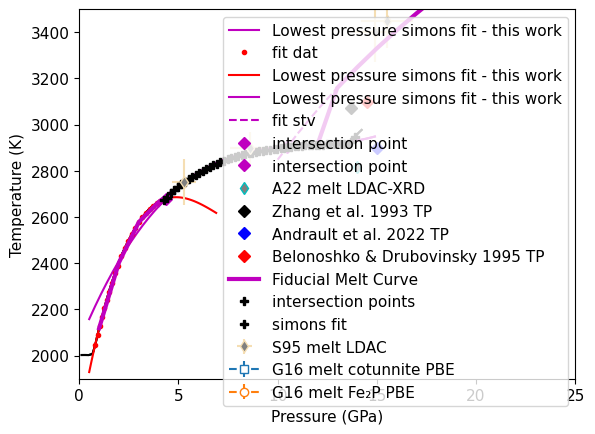

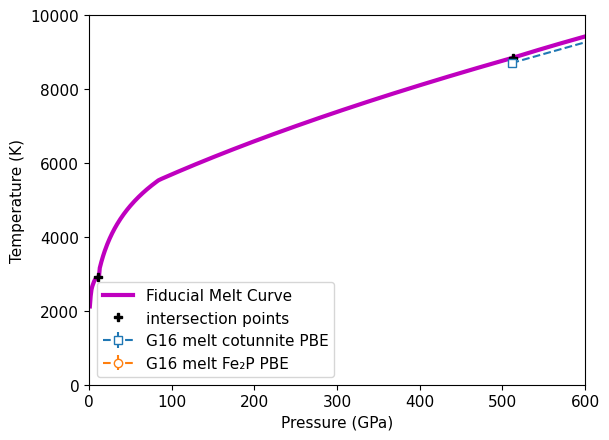

In [10]:

plt.plot(stsmcsmooth.P,stsmcsmooth.T,'m-',linewidth=3,label='Fiducial Melt Curve')
plt.errorbar(eosdat_list[G16mc['id']].P[5:8],eosdat_list[G16mc['id']].T[5:8],fmt='s--',mfc='white',yerr=eosdat_list[G16mc['id']].T_std[5:8],label=G16mcb['lab']) # cotunnite structure
plt.errorbar(eosdat_list[G16mc['id']].P[8:11],eosdat_list[G16mc['id']].T[8:11],fmt='o--',mfc='white',yerr=eosdat_list[G16mc['id']].T_std[8:11],label=G16mcc['lab']) # Fe2P structure

plt.plot([p1,p2],[t1,t2],'kP',label='intersection points')
plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.legend()
plt.show()
plt.plot(stsmcsmooth.P,stsmcsmooth.T,'m-',linewidth=3,label='Fiducial Melt Curve')
plt.errorbar(eosdat_list[G16mc['id']].P[5:8],eosdat_list[G16mc['id']].T[5:8],fmt='s--',mfc='white',yerr=eosdat_list[G16mc['id']].T_std[5:8],label=G16mcb['lab']) # cotunnite structure
plt.errorbar(eosdat_list[G16mc['id']].P[8:11],eosdat_list[G16mc['id']].T[8:11],fmt='o--',mfc='white',yerr=eosdat_list[G16mc['id']].T_std[8:11],label=G16mcc['lab']) # Fe2P structure

plt.plot([p1,p2],[t1,t2],'kP',label='intersection points')

# Luo et al. MD model
# single phase stishovite melting calculation
#plt.plot([20,40,60,80,120],[3625,4500,5500,6000,7000],'kD')


plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.xlim(0,600)
plt.ylim(0,10000)
plt.legend()
plt.show()

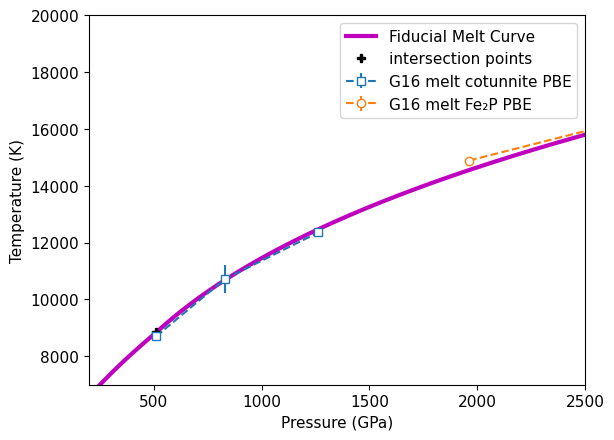

In [11]:
plt.plot(stsmcsmooth.P,stsmcsmooth.T,'m-',linewidth=3,label='Fiducial Melt Curve')
plt.errorbar(eosdat_list[G16mc['id']].P[5:8],eosdat_list[G16mc['id']].T[5:8],fmt='s--',mfc='white',yerr=eosdat_list[G16mc['id']].T_std[5:8],label=G16mcb['lab']) # cotunnite structure
plt.errorbar(eosdat_list[G16mc['id']].P[8:11],eosdat_list[G16mc['id']].T[8:11],fmt='o--',mfc='white',yerr=eosdat_list[G16mc['id']].T_std[8:11],label=G16mcc['lab']) # Fe2P structure

plt.plot([p1,p2],[t1,t2],'kP',label='intersection points')
plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.xlim(200,2500)
plt.ylim(7000,20000)
plt.legend()
plt.show()

## Density on Melt Curve - Liquidus


FIT EOS a =  [ 288.47170779 -172.4174306    27.69796636]
FIT EOS cov =  [[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
Saved EOS fit in rho_l_fit_quadratic.txt
Saved EOS fit in readable file rho_l_fit_quadratic-readable.txt
rms =  13.536838173636669


/Users/sts/anaconda3/envs/silicapaper/lib/python3.13/site-packages/scipy/odr/_odrpack.py:394: RuntimeWarning: divide by zero encountered in divide
  return 1./np.power(sd, 2)


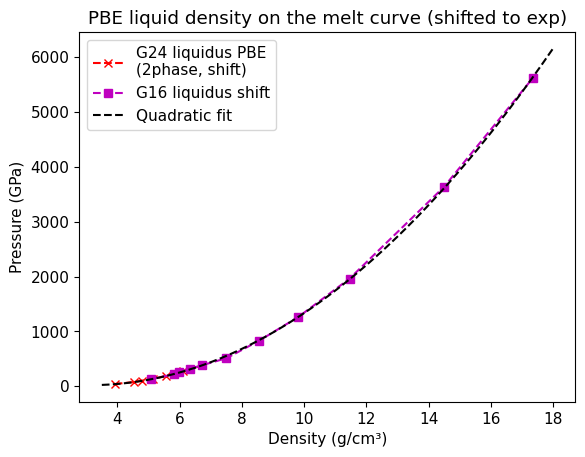

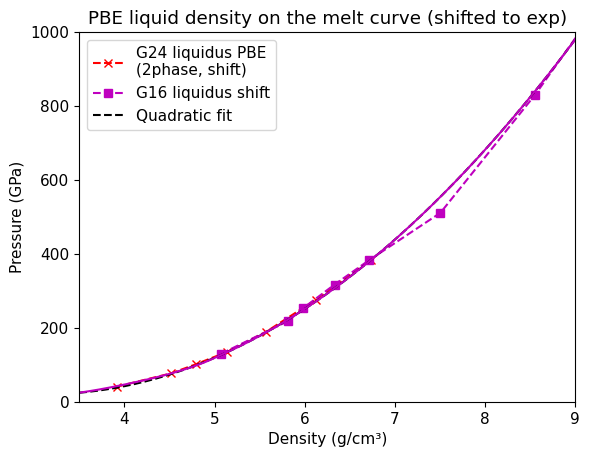

In [12]:

plt.plot(eosdat_list[G24mclrho['id']].rho_liquid+pbe_liquid_density_shift,eosdat_list[G24mclrho['id']].P_liquid,'x--',color='red',label=G24mclrho['lab']+'\n(2phase, shift)')
plt.plot(eosdat_list[G16mc['id']].rho_l+pbe_liquid_density_shift,eosdat_list[G16mc['id']].P,'s--',color='m',label='G16 liquidus shift') # cotunnite structure


xxx = np.concatenate((eosdat_list[G24mclrho['id']].rho_liquid+pbe_liquid_density_shift,eosdat_list[G16mc['id']].rho_l+pbe_liquid_density_shift))
yyy = np.concatenate((eosdat_list[G24mclrho['id']].P_liquid,eosdat_list[G16mc['id']].P))
rrr = np.concatenate((np.zeros(len(eosdat_list[G24mclrho['id']].P_liquid)),np.zeros(len(eosdat_list[G16mc['id']].P))+1))
res = np.polyfit(xxx,yyy,2)
rrr_list = [eosdat_list[G24mclrho['id']].reflist[1][0],eosdat_list[G16mc['id']].reflist[1][0]]

# initialize the HPeos_Fit class
rho_l_fit = hp.HPeos_Fit()
rho_l_fit.material = 'SiO2 liquid'
rho_l_fit.formula = 'SiO2'
rho_l_fit.x = xxx
rho_l_fit.f = yyy
rho_l_fit.x_std = np.zeros(len(xxx))
rho_l_fit.f_std = np.zeros(len(yyy))
rho_l_fit.refid = rrr
rho_l_fit.reflist = rrr_list
rho_l_fit.x_var = 'rho'
rho_l_fit.f_var = 'P'
rho_l_fit.x_units = 'g/cm3'
rho_l_fit.f_units = 'GPa'
rho_l_fit.x_desc = 'Density'
rho_l_fit.f_desc = 'Pressure'
rho_l_fit.phase_fit = 'liquid'
rho_l_fit.remlist.append('Fit to PBE DFT liquidus calculations.')
DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
rho_l_fit.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]

rho_l_fit.curvetype = 'quadratic'
rho_l_fit.outputfitpath = outputfitpath # in load_paths.py
rho_l_fit.filename = 'rho_l_fit_quadratic'
rho_l_fit.fit()
print('FIT EOS a = ',rho_l_fit.a)
print('FIT EOS cov = ',rho_l_fit.cov)
rho_l_fit.savejson()
rho_l_fit.savereadable()
print('rms = ',rho_l_fit.rms)


mc_new = hp.HPeos_MeltCurve()
mc_new.rho_l = np.arange(3.5,18,.01)
mc_new.P_l = rho_l_fit.a[0]+rho_l_fit.a[1]*mc_new.rho_l+rho_l_fit.a[2]*mc_new.rho_l*mc_new.rho_l

plt.plot(mc_new.rho_l,mc_new.P_l,'k--',label='Quadratic fit')
plt.title('PBE liquid density on the melt curve (shifted to exp)')
plt.legend()
plt.xlabel('Density (g/cm³)')
plt.ylabel('Pressure (GPa)')
plt.show()


plt.plot(eosdat_list[G24mclrho['id']].rho_liquid+pbe_liquid_density_shift,eosdat_list[G24mclrho['id']].P_liquid,'x--',color='red',label=G24mclrho['lab']+'\n(2phase, shift)')
plt.plot(eosdat_list[G16mc['id']].rho_l+pbe_liquid_density_shift,eosdat_list[G16mc['id']].P,'s--',color='m',label='G16 liquidus shift') # cotunnite structure

plt.plot(mc_new.rho_l,mc_new.P_l,'k--',label='Quadratic fit')
plt.plot(stsmcsmooth.rho,stsmcsmooth.P,'m-')

plt.title('PBE liquid density on the melt curve (shifted to exp)')
plt.xlim(3.5,9)
plt.ylim(0,1000)
plt.legend()
plt.xlabel('Density (g/cm³)')
plt.ylabel('Pressure (GPa)')

plt.show()


## Density on Melt Curve - Solidus

The density difference is limited to 2% at high pressures and the dS is set to sqrt(2)R

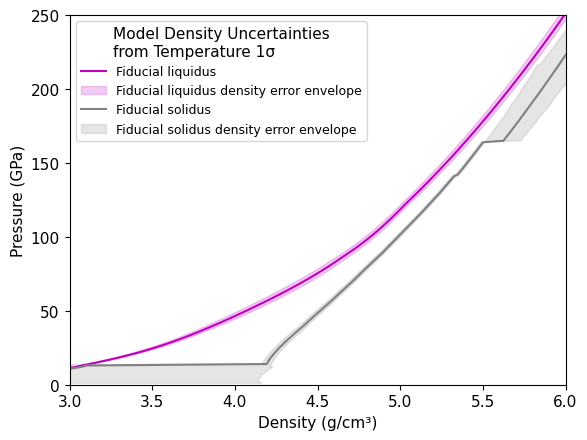

In [13]:
plt.plot(stsmcsmooth.rho,stsmcsmooth.P,'m-',label='Fiducial liquidus')
ind = np.where(stsmcsmooth.rho<50)
plt.fill_betweenx(stsmcsmooth.P[ind],stsmcsmooth.rho_low[ind],stsmcsmooth.rho_high[ind],color='m',alpha=0.2,label='Fiducial liquidus density error envelope')
plt.plot(stsmcsmooth.rho_s,stsmcsmooth.P,'-',color=colsolidus,label='Fiducial solidus')
ind = np.where(stsmcsmooth.rho<50)
plt.fill_betweenx(stsmcsmooth.P[ind],stsmcsmooth.rho_s[ind]-(stsmcsmooth.rho_s_high[ind]-stsmcsmooth.rho_s[ind]),stsmcsmooth.rho_s_high[ind],color=colsolidus,alpha=0.2,label='Fiducial solidus density error envelope')
plt.legend(fontsize=lfss,title='Model Density Uncertainties\nfrom Temperature 1σ')
plt.ylim(0,250)
plt.xlim(3.,6.)
plt.xlabel('Density (g/cm³)')
plt.ylabel('Pressure (GPa)')
plt.show()

In [14]:
plt.plot(stsmcsmooth.P,(stsmcsmooth.rho-stsmcsmooth.rho_low)/stsmcsmooth.rho,label='liquidus low')
plt.plot(stsmcsmooth.P,(stsmcsmooth.rho_high-stsmcsmooth.rho)/stsmcsmooth.rho,label='liquidus high')
plt.plot(stsmcsmooth.P,(stsmcsmooth.rho_s-stsmcsmooth.rho_s_low)/stsmcsmooth.rho_s,label='solidus low')
plt.plot(stsmcsmooth.P,(stsmcsmooth.rho_s_high-stsmcsmooth.rho_s)/stsmcsmooth.rho_s,label='solidus high')
plt.xlim(0,500)
plt.ylim(0,.015)
plt.legend(fontsize=lfss)
plt.xlabel('Pressure (GPa)')
plt.ylabel('Fractional uncertainty in density')


Text(0, 0.5, 'Fractional uncertainty in density')

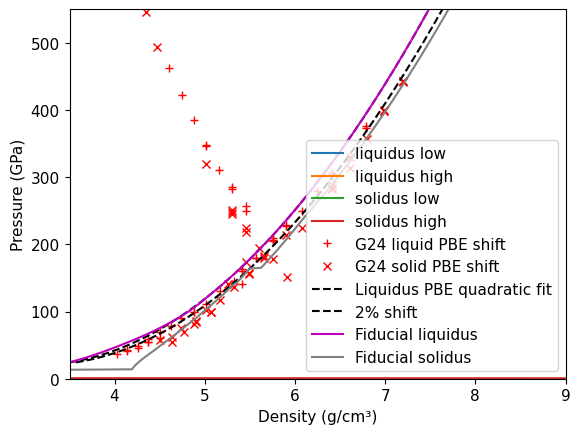

In [15]:

# Geng Mohn calcs
plt.plot(eosdat_list[G24mcl['id']].rho_liquid+pbe_liquid_density_shift,eosdat_list[G24mcl['id']].P_liquid,'+',color='red',label=G24mcl['lab']+ ' shift')
plt.plot(eosdat_list[G24mcs['id']].rho_solid+pbe_liquid_density_shift,eosdat_list[G24mcs['id']].P_solid,'x',color='red',label=G24mcs['lab']+' shift')

plt.plot(mc_new.rho_l,mc_new.P_l,'k--',label='Liquidus PBE quadratic fit')
plt.plot(mc_new.rho_l*1.02,mc_new.P_l,'k--',label='2% shift')
plt.plot(stsmcsmooth.rho,stsmcsmooth.P,'m-',label='Fiducial liquidus')
plt.plot(stsmcsmooth.rho_s,stsmcsmooth.P,'-',color=colsolidus,label='Fiducial solidus')

plt.legend()
plt.ylim(0,550)
plt.xlim(3.5,9)
plt.xlabel('Density (g/cm³)')
plt.ylabel('Pressure (GPa)')
plt.show()
#x,y=intersection(mc_new.rho_l,mc_new.P_l,stsmcsmooth.rho,stsmcsmooth.P)
#print(x,y)

## Check the Clausius Clapeyron Relation

The transition from sft to pyrite is not included and a high pressure value for dS and dV are imposed for now.

The melt curve slope is given by

$$\frac{dT}{dP} = \frac{dV}{dS}$$

{cite:t}`Andrault2020` found that the melt curve of stishovite is initially steep and then flattens at about 40 GPa. Upon reaching the CaCl$_2$-type phase, the melt curve steepens again. {cite:t}`Andrault2020` suggest that the entropy difference with the high-density melt must be decreasing.

For now, entropy is fixed to a constant on the melt curve near the transition from pyrite to cotunnite structure.

Note that the CN in glass has an abrupt transition but the DFT-PBE calculated CN in liquid is a more graduate transition. So not a sharp LDM to HDM curvature change.

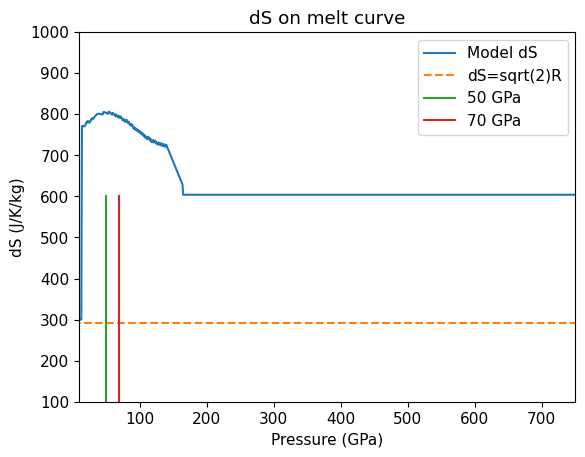

287.74323814600064


In [16]:
pmax=750 # GPa
plt.plot(stsmcsmooth.P, stsmcsmooth.S_l-stsmcsmooth.S_s,label='Model dS')
plt.plot([0,pmax],[  3*.7*Rgas/(sio2mol/1000), 3*.7*Rgas/(sio2mol/1000)],'--',label='dS=sqrt(2)R')
plt.xlabel('Pressure (GPa)')
plt.ylabel('dS (J/K/kg)')
plt.title('dS on melt curve')

plt.plot([50,50],[100,600],label='50 GPa')
plt.plot([70,70],[100,600],label='70 GPa')
plt.xlim(10,pmax)
plt.ylim([100,1000])
plt.legend()
plt.show()

print(3*np.log(2)*Rgas/(sio2mol/1000))

644.1089825741059


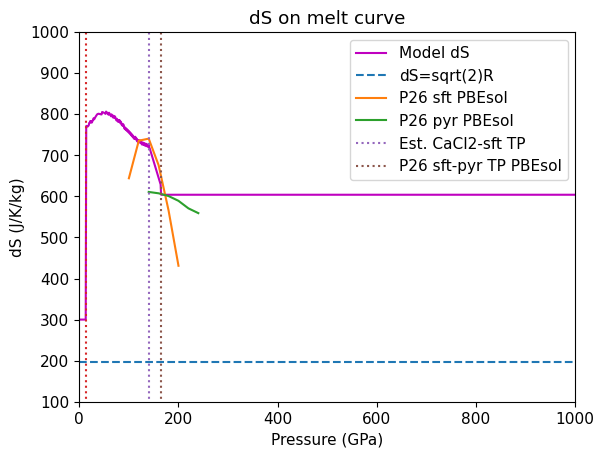

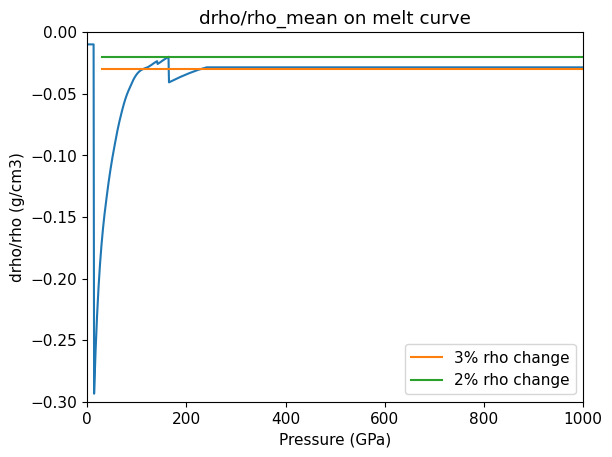

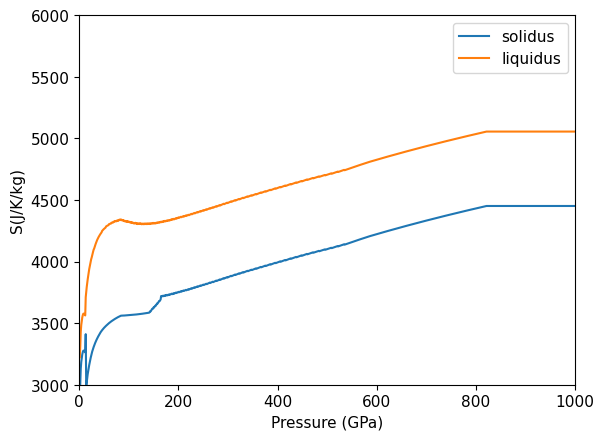

In [17]:
pmax=1000 # GPa
plt.plot(stsmcsmooth.P, stsmcsmooth.S_l-stsmcsmooth.S_s,'m-',label='Model dS')
plt.plot([0,pmax],[ 1.414*Rgas/(sio2mol/1000), 1.414*Rgas/(sio2mol/1000)],'--',label='dS=sqrt(2)R')
print(38.7/(sio2mol/1000))
plt.plot([100,120,140,160,180,200],np.asarray([38.7,44.2,44.5,40.6,34,25.9])/(sio2mol/1000),label='P26 sft PBEsol')
plt.plot([140,160,180,200,220,240],np.asarray([36.7,36.5,36.1,35.4,34.3,33.6])/(sio2mol/1000),label='P26 pyr PBEsol')
plt.xlabel('Pressure (GPa)')
plt.ylabel('dS (J/K/kg)')
plt.title('dS on melt curve')

plt.plot([14,14],[0,pmax],':')
plt.plot([Pt3,Pt3],[0,pmax],':',label='Est. CaCl2-sft TP')
plt.plot([165,165],[0,pmax],':',label='P26 sft-pyr TP PBEsol')

#plt.plot([50,50],[100,750])
plt.xlim(0,pmax)
plt.ylim([100,pmax])
plt.legend()
plt.show()
plt.plot(stsmcsmooth.P, (stsmcsmooth.rho-stsmcsmooth.rho_s)/((stsmcsmooth.rho+stsmcsmooth.rho_s)/2))


plt.xlabel('Pressure (GPa)')
plt.ylabel('drho/rho (g/cm3)')
plt.title('drho/rho_mean on melt curve')
plt.plot([30,pmax],[-.03,-.03],label='3% rho change')
plt.plot([30,pmax],[-.02,-.02],label='2% rho change')
#plt.plot([30,pmax],[-.01,-.01],label='1% rho change')
plt.xlim(0,pmax)
plt.ylim(-.3,0)
plt.legend()
plt.show()
plt.plot(stsmcsmooth.P,stsmcsmooth.S_s,label='solidus')
plt.plot(stsmcsmooth.P,stsmcsmooth.S_l,label='liquidus')

plt.xlabel('Pressure (GPa)')
plt.ylabel('S(J/K/kg)')
plt.xlim(0,pmax)
plt.ylim(3000,6000)
plt.legend()
plt.show()

In [18]:
parkp = np.asarray([140,160,180,200,220,240])
parkdv = np.asarray([.319,.276,.243,.215,.191,.172]) * 0.602214 / 20.028
print(parkdv)

[0.00959188 0.00829893 0.00730667 0.00646475 0.0057431  0.0051718 ]


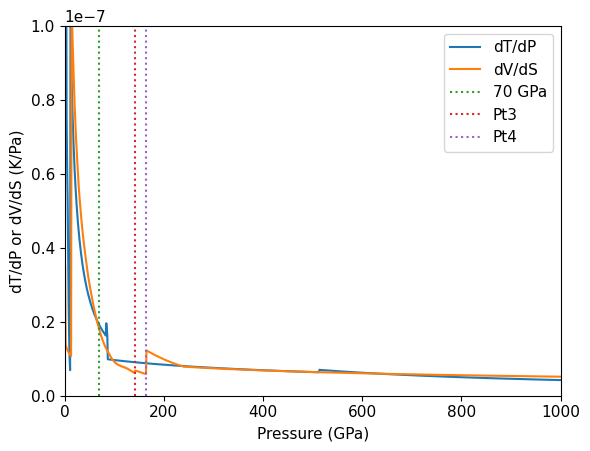

In [19]:
dtdp=np.gradient(stsmcsmooth.T,1.e9) # K/Pa
plt.plot(stsmcsmooth.P,dtdp,label='dT/dP')

dv = ((1/stsmcsmooth.rho)-(1/stsmcsmooth.rho_s))/1000. # m3/kg
ds = stsmcsmooth.S_l-stsmcsmooth.S_s #J/K/kg
plt.plot(stsmcsmooth.P,dv/ds,label='dV/dS')
#plt.plot(stsmcsmooth.P,dv/ds*.8,'--',label='.8*dV/dS')
plt.xlim(0,pmax)
plt.ylim(0,1.e-7)
plt.xlabel('Pressure (GPa)')
plt.ylabel('dT/dP or dV/dS (K/Pa)')
plt.plot([70,70],[0,1.e-7],':',label='70 GPa')
plt.plot([Pt3,Pt3],[0,1.e-7],':',label='Pt3')
plt.plot([165,165],[0,1.e-7],':',label='Pt4')
plt.legend()
plt.show()

[0.00959188 0.00829893 0.00730667 0.00646475 0.0057431  0.0051718 ]
[104.25479823 120.4973936  136.86123718 154.68502621 174.12188814
 193.35628276]
[0.01049811 0.00411605 0.0039912  ... 0.001583   0.00158289 0.00158278]
[0.00943121 0.02405459 0.02480704 ... 0.51629745 0.51633308 0.51636871]


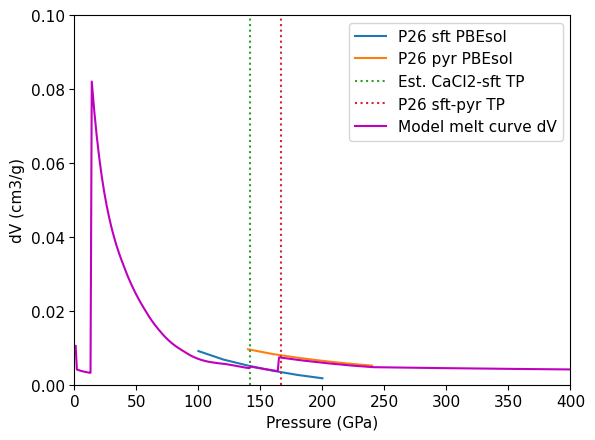

In [20]:

#Deng dV in A3/atom
plt.plot([100,120,140,160,180,200],np.asarray([.303,.227,.172,.126,.088,.058])*0.602214 / 20.028,label='P26 sft PBEsol')
plt.plot([140,160,180,200,220,240],np.asarray([.319,.276,.243,.215,.191,.172])*0.602214 / 20.028,label='P26 pyr PBEsol')
parkdv = (np.asarray([.319,.276,.243,.215,.191,.172]))* 0.602214 / 20.028 # correct
print(parkdv)
print(1/parkdv)
plt.plot([Pt3,Pt3],[0,.1],':',label='Est. CaCl2-sft TP')
plt.plot([167,167],[0,.1],':',label='P26 sft-pyr TP')
dv = ((1/stsmcsmooth.rho)-(1/stsmcsmooth.rho_s))# cm3/g
print(dv)
drho = ((stsmcsmooth.rho_s)-(stsmcsmooth.rho))# g/cm3
print(drho)
#ds = stsmcsmooth.S_l-stsmcsmooth.S_s #J/K/kg
plt.plot(stsmcsmooth.P,dv,'m-',label='Model melt curve dV')
plt.xlim(0,400)
plt.ylim(0,.1)
plt.xlabel('Pressure (GPa)')
plt.ylabel('dV (cm3/g)')
plt.legend()
plt.show()

## Estimate triple points

Linear extrapolation of low-pressure boundaries for Stv-CaCl2 and CaCl2 to Sft


In [21]:
# Cst-Stv TP
print('# Cst-Stv TP:')
print('Pt1 = 13.7 # GPa') # using pressure from Zhang et al. 1993
print('Tt1 = ',np.interp(13.7,stsmcsmooth.P,stsmcsmooth.T),' # K') # Zhang et al. 1993 estimated 2800C

print('Compare to define_eos values = ',Pt1,Tt1)


# Cst-Stv TP:
Pt1 = 13.7 # GPa
Tt1 =  3220.7975619137674  # K
Compare to define_eos values =  13.7 3220.7975619137674


In [22]:
# Stv-CaCl2-type second order TP
# This triple point is the intersection of the Tsuchiya et al. GGA
zzz = np.where(eosdat_list[T04pba['id']].T > 1000.)[0]
res = np.polyfit(np.flip(eosdat_list[T04pba['id']].P[zzz]),np.flip(eosdat_list[T04pba['id']].T[zzz]),1)
print('RES a=',res)
print('4000 K pressure = ',np.interp(4000,np.flip(eosdat_list[T04pba['id']].T[zzz]),np.flip(eosdat_list[T04pba['id']].P[zzz])))
print('Pt12 = ',np.interp(4000,np.flip(eosdat_list[T04pba['id']].T[zzz]),np.flip(eosdat_list[T04pba['id']].P[zzz])),' GPa')
print('Compare to define_eos values = ',Pt12)
print('')

parr = np.arange(50,100,1) # pressure
tarr = res[1]+res[0]*parr # temperature
# find intersection with fudicial melt curve
x,y = intersection(parr,tarr,stsmcsmooth.P,stsmcsmooth.T)
print('Triple point')
print(x,y)
print('# Stv-CaCl2 TP:')
print('Pt2 = ',x[0],' # GPa')
print('Tt2 = ',y[0],' # K')

print('Compare to define_eos values = ',Pt2,Tt2)

RES a= [  168.39552949 -9390.03914284]
4000 K pressure =  62.82706956833862
Pt12 =  62.82706956833862  GPa
Compare to define_eos values =  62.827

Triple point
[88.91220821] [5582.37923764]
# Stv-CaCl2 TP:
Pt2 =  88.91220821388308  # GPa
Tt2 =  5582.379237642232  # K
Compare to define_eos values =  88.91220821388308 5582.379237642232


In [23]:
# CaCl2 to sft TP
zzz = np.where(eosdat_list[T04pbb['id']].T > 1000.)[0]
res = np.polyfit(np.flip(eosdat_list[T04pbb['id']].P[zzz]),np.flip(eosdat_list[T04pbb['id']].T[zzz]),1)
print('RES b=',res)
print('4000 K pressure = ',np.interp(4000,np.flip(eosdat_list[T04pbb['id']].T[zzz]),np.flip(eosdat_list[T04pbb['id']].P[zzz])))
print('Pt23 = ',np.interp(4000,np.flip(eosdat_list[T04pbb['id']].T[zzz]),np.flip(eosdat_list[T04pbb['id']].P[zzz])),' # GPa')
print('Compare to define_eos values = ',Pt23)
print('')

parr = np.arange(50,150,1) # pressure
tarr = res[1]+res[0]*parr # temperature
# find intersection with fudicial melt curve
x,y = intersection(parr,tarr,stsmcsmooth.P,stsmcsmooth.T)
print('Triple point')
print(x,y)
print('# CaCl2-sft TP:')
print('Pt3 = ',x[0],' # GPa')
print('Tt3 = ',y[0],' # K')

print('Compare to define_eos values = ',Pt3,Tt3)

RES b= [   173.75113152 -18503.2972858 ]
4000 K pressure =  113.4110155408729
Pt23 =  113.4110155408729  # GPa
Compare to define_eos values =  113.4110155408729

Triple point
[141.47365402] [6077.91018034]
# CaCl2-sft TP:
Pt3 =  141.47365401777512  # GPa
Tt3 =  6077.910180343331  # K
Compare to define_eos values =  141.47365401777512 6077.910180343331


In [24]:
# Low density melt to high density melt approx 40 GPa from Andrault et al. 2022

# Second order liquid transition around 40 GPa from Andrault et al. 2022
print('# LDM-HDM Transition:')
print('Ptm = 40 # GPa') 
print('Ttm = ',np.interp(40,stsmcsmooth.P,stsmcsmooth.T),' # K') 

print('Compare to define_eos values = ',Ptm,Ttm)
# Second order liquid transition around 40 GPa from Andrault et al. 2022
print('# LDM-HDM Transition:')
print('Ptm = 50 # GPa') 
print('Ttm = ',np.interp(50,stsmcsmooth.P,stsmcsmooth.T),' # K') 

print('Compare to define_eos values = ',Ptm,Ttm)


# LDM-HDM Transition:
Ptm = 40 # GPa
Ttm =  4552.0558269548055  # K
Compare to define_eos values =  50 4841.313561513845
# LDM-HDM Transition:
Ptm = 50 # GPa
Ttm =  4841.313561513845  # K
Compare to define_eos values =  50 4841.313561513845


## Hugoniot crossing the melt curve

In [25]:
# FS enters liquid field
x,y = intersection(fs_hug_liq.P,fs_hug_liq.T,stsmcsmooth.P,stsmcsmooth.T)
print(x,y)

print('fs_startliq_P = ',x[0],' # GPa')

print('Compare to define_eos values = ',fs_startliq_P)


[90.51739] [5598.12759231]
fs_startliq_P =  90.51739000382202  # GPa
Compare to define_eos values =  90.5101601196313


In [26]:
# FS crosses solidus
x,y = intersection(fs_hug_stv.rho,fs_hug_stv.P,stsmcsmooth.rho_s,stsmcsmooth.P)
print(x,y)

print('fs_startsol_P = ',y[1],' # GPa')

print('Compare to define_eos values = ',fs_startsol_P)


[4.292826   4.73330942] [27.64421059 72.32639754]
fs_startsol_P =  72.3263975407623  # GPa
Compare to define_eos values =  72.32862722602232


In [27]:
# qtz enters liquid field
x,y = intersection(qtz_hug_liq.P,qtz_hug_liq.T,stsmcsmooth.P,stsmcsmooth.T)
print(x,y)

print('qtz_startliq_P = ',x[0],' # GPa')

print('Compare to define_eos values = ',qtz_startliq_P)


[145.80938585] [6117.08010474]
qtz_startliq_P =  145.80938585293262  # GPa
Compare to define_eos values =  145.80682496155464


In [28]:
# Qtz sold region crosses solidus
x,y = intersection(qtz_hug_solid.rho,qtz_hug_solid.P,stsmcsmooth.rho_s,stsmcsmooth.P)
print(x,y)

print('qtz_startsol_P = ',y[0],' # GPa')

print('Compare to define_eos values = ',qtz_startsol_P)


[4.99116474] [100.50773756]
qtz_startsol_P =  100.50773755669458  # GPa
Compare to define_eos values =  100.50773755669458


In [29]:
# Qtz stv crosses stv-CaCl2 boundary

zzz = np.where(eosdat_list[T04pba['id']].T > 1000.)[0]
res = np.polyfit(np.flip(eosdat_list[T04pba['id']].P[zzz]),np.flip(eosdat_list[T04pba['id']].T[zzz]),1)
parr = np.arange(50,100,1) # pressure
tarr = res[1]+res[0]*parr # temperature
# find intersection with fudicial melt curve
x,y = intersection(qtz_hug_stv.P,qtz_hug_stv.T,parr,tarr)

print('qtz_trans_cacl2_P = ',x[0],' # GPa')

print('Compare to define_eos values = ',qtz_trans_cacl2_P)


qtz_trans_cacl2_P =  82.58142670722148  # GPa
Compare to define_eos values =  82.58142670722148


In [30]:
# cst enters liquid field
x,y = intersection(cst_hug_liq.P,cst_hug_liq.T,stsmcsmooth.P,stsmcsmooth.T)
print(x,y)

print('cst_liquidus_P = ',x[0],' # GPa')

print('Compare to define_eos values = ',cst_liquidus_P)


[183.61347134] [6449.00922951]
cst_liquidus_P =  183.61347134392335  # GPa
Compare to define_eos values =  183.61347134392335


In [31]:
# Cst cacl2 region crosses solidus
x,y = intersection(cst_hug_cacl2.rho,cst_hug_cacl2.P,stsmcsmooth.rho_s,stsmcsmooth.P)
print(x,y)

print('cst_solidus_P = ',y[0],' # GPa')
print('Compare to define_eos values = ',cst_solidus_P)


[5.20487876] [125.53423056]
cst_solidus_P =  125.53423056253213  # GPa
Compare to define_eos values =  125.53423196515627


In [32]:
# stv enters liquid field in PT space
x,y = intersection(stv_hug_liq.P,stv_hug_liq.T,stsmcsmooth.P,stsmcsmooth.T)
print(x,y)
print('stv_liquidus_P = ',x[0],' # GPa')

print('Compare to define_eos values = ',stv_liquidus_P)

[632.94294278] [9622.88901809]
stv_liquidus_P =  632.9429427843702  # GPa
Compare to define_eos values =  632.9429427843702


In [33]:
# stv crosses the fitted solidus density -- this is not correct in PVT relationships
x,y = intersection(stv_hug_liq.rho,stv_hug_liq.P,stsmcsmooth.rho_s,stsmcsmooth.P)
print(x,y)
print('stv_solidus_P = ',y[0],' # GPa')

print('Compare to define_eos values = ',stv_solidus_P)

[7.7255964] [555.26628334]
stv_solidus_P =  555.2662833351458  # GPa
Compare to define_eos values =  490.63813073715124


In [34]:
# stv enters liquid field in PT space

plt.plot(stv_hug_liq.P,stv_hug_liq.T,'k-',label='New Stv Hugoniot')
plt.plot(stsmcsmooth.P,stsmcsmooth.T,'m-',label='Fiducial melt curve')
plt.errorbar(eosdat_list[G16mc['id']].P[5:8],eosdat_list[G16mc['id']].T[5:8],fmt='s--',mfc='white',yerr=eosdat_list[G16mc['id']].T_std[5:8],label=G16mcb['lab']) # cotunnite structure
plt.ylabel('Temperature (K)')
plt.xlabel('Pressure (GPa)')

x,y = intersection(stv_hug_liq.P,stv_hug_liq.T,stsmcsmooth.P,stsmcsmooth.T)
print(x,y)
plt.plot(x,y,'kD')
xl=np.copy(x)
print('stv_liquidus_P = ',x[0],' # GPa')

print('Compare to define_eos values = ',stv_liquidus_P)
plt.legend(fontsize=lfss)
plt.xlim(0,1500)
plt.ylim(5000,25000)

[632.94294278] [9622.88901809]
stv_liquidus_P =  632.9429427843702  # GPa
Compare to define_eos values =  632.9429427843702


(5000.0, 25000.0)

In [35]:
# estimate stv solidus using density information from G16
# assume this increase in density
# the PVT for melt cuve intersection with stv Hugoniot is more self-consistent with cotunnite points that are denser than the fiducial solidus
scale=1.02

shift=pbe_liquid_density_shift # PBE density correction from dft-offset.ipynb

plt.plot(stv_hug_liq.rho,stv_hug_liq.P,'-',color='firebrick',linewidth=2,label='New Stv Hugoniot')

# additional pyrite density points not helpful here
#plt.plot((eosdat_list[G16mcpyr['id']].rho_l+shift),eosdat_list[G16mcpyr['id']].P,'o',markersize=10,label=G16mcpyr['lab']) # cotunnite structure

# Gonzales et al. 2016 very high rpessure melt curve points
plt.plot(eosdat_list[G16mcpyr['id']].rho_l+shift,eosdat_list[G16mcpyr['id']].P,'d--',color='orange',label=G16mc['lab']+' shifted') # pyrite structure
plt.plot(eosdat_list[G16mc['id']].rho_l[5:8]+shift,eosdat_list[G16mc['id']].P[5:8],'s--',color='blue',label=G16mcb['lab']+' shifted') # cotunnite structure
plt.plot((eosdat_list[G16mc['id']].rho_l[5:8]+shift)*scale,eosdat_list[G16mc['id']].P[5:8],'s--',color='grey',label='Est. cotunnite solidus') # cotunnite structure

#plt.errorbar(eosdat_list[G16mc['id']].rho_l[1:8]+shift,eosdat_list[G16mc['id']].P[1:8],fmt='s--',mfc='white',mec='m',color='m',label='G16 liquidus shift') # cotunnite structure
#plt.plot((eosdat_list[G16mc['id']].rho_l[1:8]+shift)*scale,eosdat_list[G16mc['id']].P[1:8],'--',color=colsolidus,label='Estimated solidus') # cotunnite structure
#plt.errorbar(eosdat_list[G16mc['id']].rho_l[8:11],eosdat_list[G16mc['id']].P[8:11],fmt='o--',mfc='white',yerr=eosdat_list[G16mc['id']].T_std[8:11],label=G16mcc['lab']) # Fe2P structure
#plt.errorbar(eosdat_list[G16mc['id']].P[::],eosdat_list[G16mc['id']].T[::],fmt='kx',yerr=eosdat_list[G16mc['id']].T_std[::],label=G16mcb['lab']+'all pts')

plt.plot(stsmcsmooth.rho,stsmcsmooth.P,'m-',label='Fiducial liquidus')
plt.plot(stsmcsmooth.rho_s,stsmcsmooth.P,'-',color=colsolidus,label='Fiducial solidus')

plt.ylim(200,1400)
plt.xlim(5.5,10)
plt.xlabel('Density (g/cm3)')
plt.ylabel('Pressure (GPa)')

#plt.plot((eosdat_list[G24mclrho['id']].rho_liquid+shift),eosdat_list[G24mclrho['id']].P_liquid,'kd--',label=G24mclrho['lab']+'\n(2phase, shift)') # cotunnite structure

# stv region crosses solidus
xxx = (eosdat_list[G16mc['id']].rho_l[1:8]+shift)*scale
yyy = eosdat_list[G16mc['id']].P[1:8]
x,y = intersection(stv_hug_liq.rho,stv_hug_liq.P,xxx,yyy)
print(x,y)
plt.plot([5,15],[xl,xl],'m:',label='Liquidus crossing from P-T')
plt.plot(x,y,'kD',label='Solidus crossing')
print('stv_solidus_P = ',y[0],' # GPa')
print('Compare to define_eos values = ',stv_solidus_P)

plt.legend(fontsize=lfss)
print('Hugoniot crosses melt curve near the pyrite-cottunite-liquid triple point from G16')

[7.52608446] [490.63813074]
stv_solidus_P =  490.63813073715124  # GPa
Compare to define_eos values =  490.63813073715124
Hugoniot crosses melt curve near the pyrite-cottunite-liquid triple point from G16


In [36]:
D26mc = np.loadtxt(silicadatadir+'deng2026_tableS1.csv',delimiter=',', skiprows=1,usecols=(1, 2, 4,9,10,11))
D26mcphase = np.loadtxt(silicadatadir+'deng2026_tableS1.csv',delimiter=',', skiprows=1,usecols=(0),dtype=str)
print(D26mcphase)
print(D26mc)

#parkp = np.asarray([140,160,180,200,220,240])
dengdv =  D26mc[:,2]* 0.602214 / 20.028
print(dengdv)
print((D26mc[:,3]-dengdv)/dengdv)

['Stishovite' 'Stishovite' 'Stishovite' 'Stishovite' 'Stishovite'
 'Stishovite' 'Stishovite' 'Post-stishovite' 'Post-stishovite'
 'Post-stishovite' 'Post-stishovite' 'Post-stishovite' 'Seifertite'
 'Seifertite' 'Seifertite' 'Seifertite' 'Seifertite' 'Seifertite'
 'Seifertite' 'Seifertite']
[[2.0000e+01 3.9400e+03 1.5700e+00 4.7210e-02 6.0610e+02 8.5395e+06]
 [4.0000e+01 4.8400e+03 8.3000e-01 2.4960e-02 8.2200e+02 1.0596e+07]
 [6.0000e+01 5.3700e+03 5.4000e-01 1.6240e-02 8.1780e+02 1.1549e+07]
 [8.0000e+01 5.7100e+03 3.7000e-01 1.1130e-02 7.4310e+02 1.1972e+07]
 [9.0000e+01 5.8500e+03 3.1000e-01 9.3200e-03 6.9740e+02 1.2088e+07]
 [1.0000e+02 5.9700e+03 2.6000e-01 7.8200e-03 7.4310e+02 1.2142e+07]
 [1.1000e+02 6.0600e+03 2.2000e-01 6.6200e-03 7.5970e+02 1.2131e+07]
 [1.2000e+02 6.1500e+03 1.8000e-01 5.4100e-03 7.4310e+02 1.2029e+07]
 [1.3000e+02 6.2200e+03 1.6000e-01 4.8100e-03 7.2650e+02 1.2021e+07]
 [1.4000e+02 6.2800e+03 1.3000e-01 3.9100e-03 7.0160e+02 1.1998e+07]
 [1.5000e+02 6.3300

## Volume change on melting

dv1,dv2,dv3,dv4= 6.0711956393945075 4.095351637870143 3.39359952251386 2.4929859157564276
[0.26719902 0.24236767 0.22594144 0.21356556 0.20843408 0.20402061
 0.2001173  0.19666824 0.19336435 0.19031636 0.18725995 0.1846385
 0.20843408 0.20402061 0.2001173  0.19666824 0.19336435 0.19031636
 0.18725995 0.1846385 ]
644.1089825741059


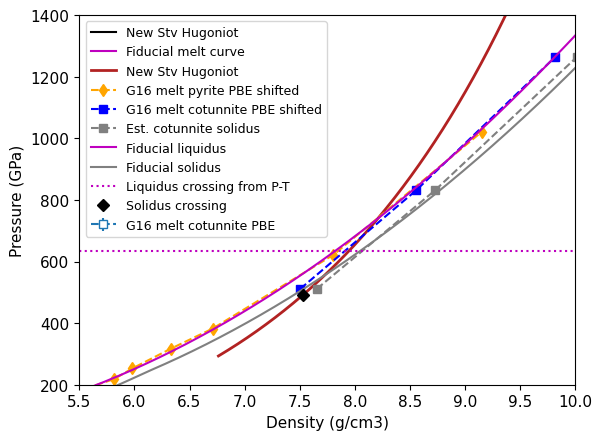

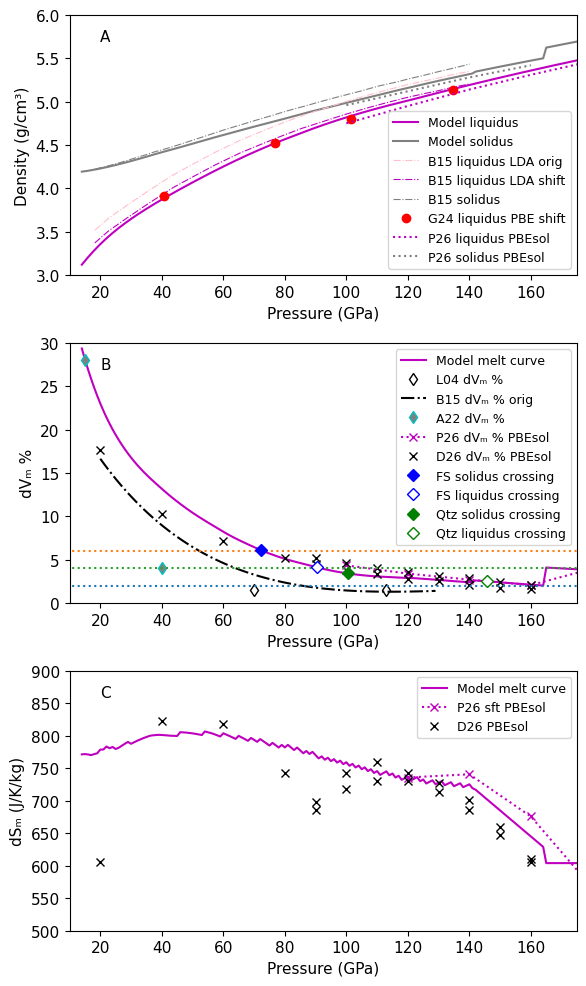

In [37]:
%run -i scripts/set_colors.py # custom colors

#B15pr = np.loadtxt(silicadatadir+'Boukare-2015-Figure1-SiO2.csv',delimiter=',',skiprows=3)
B15pr_sol = np.loadtxt(silicadatadir+'Boukare-2015-Fig1-solidus-density.csv',delimiter=',',skiprows=3)
B15pr_liq = np.loadtxt(silicadatadir+'Boukare-2015-Fig1-liquidus-density.csv',delimiter=',',skiprows=3)

ress = np.polyfit(B15pr_sol[:,0],B15pr_sol[:,1],2)
resl = np.polyfit(B15pr_liq[:,0],B15pr_liq[:,1],3)
B15pp = np.arange(110)+20
B15rhol = resl[3]+resl[2]*B15pp+resl[1]*B15pp*B15pp+resl[0]*B15pp*B15pp*B15pp
B15rhos = ress[2]+ress[1]*B15pp+ress[0]*B15pp*B15pp

ind = np.where(stsmcsmooth.P >= Pt1)[0]

fig,ax=plt.subplots(3,1,figsize=fsize5)

#plt.plot(gm24mc.P,gm24mc.T,'-',color='c',label='G24 MC 2phase PBE')
ax[0].plot(stsmcsmooth.P[ind],stsmcsmooth.rho[ind],'m-',label='Model liquidus')
ax[0].plot(stsmcsmooth.P[ind],stsmcsmooth.rho_s[ind],'-',color=sol_col,label='Model solidus')
#ax[0].plot(B15pp,B15rhol,'k--')
#ax[0].plot(B15pp,B15rhos,'k--')



ax[0].plot(B15pr_liq[:,0],B15pr_liq[:,1],'-.',markersize=1,color='pink',label='B15 liquidus LDA orig',linewidth=0.8)
ax[0].plot(B15pr_liq[:,0],B15pr_liq[:,1]+lda_liquid_density_shift,'-.',markersize=1,color='m',label='B15 liquidus LDA shift',linewidth=0.8)

ax[0].plot(B15pr_sol[:,0],B15pr_sol[:,1],'-.',markersize=1,color=sol_col,label='B15 solidus',linewidth=0.8)

#ax[0].plot(eosdat_list[G24mclrho['id']].P_liquid,eosdat_list[G24mclrho['id']].rho_liquid,'x',markersize=6,color='red',label=G24mclrho['lab']+ ' orig')

ax[0].plot(eosdat_list[G24mclrho['id']].P_liquid,eosdat_list[G24mclrho['id']].rho_liquid+pbe_liquid_density_shift,'o',markersize=6,color='red',label=G24mclrho['lab']+ ' shift')
# Park & Deng 2025 PBEsol and SCAN
ind = np.asarray([0,1,2,3,9,10,11,12]) #PBEsol
ax[0].plot(eosdat_list[P25mcpbe['id']].P[ind],eosdat_list[P25mcpbe['id']].rho_l[ind],':',color='m',label='P26 liquidus PBEsol')#P25mcpbe['lab'])
ind = np.asarray([0,1,2,3])#PBEsol
ax[0].plot(eosdat_list[P25mcpbe['id']].P[ind],eosdat_list[P25mcpbe['id']].rho_s[ind],':',color=sol_col,label='P26 solidus PBEsol')#P25mcpbe['lab'])

ax[0].set_xlim(10,175)
ax[0].set_ylim(3,6)
ax[0].set_xlabel('Pressure (GPa)')
ax[0].set_ylabel('Density (g/cm³)')
ax[0].text(20,5.7,'A',fontsize=fss)
ax[0].legend(fontsize=lfss)
#ax[1].set_prop_cycle(custom_cycler)
#dv = (stsmcsmooth.rho_s/stsmcsmooth.rho-1)*100
#dv = ((stsmcsmooth.rho_s-stsmcsmooth.rho)/((stsmcsmooth.rho_s+stsmcsmooth.rho_s)/2))*100
#dv = ((stsmcsmooth.rho_s-stsmcsmooth.rho)/stsmcsmooth.rho_s)*100
dv = (1/stsmcsmooth.rho-1/stsmcsmooth.rho_s)/((1/stsmcsmooth.rho_s+1/stsmcsmooth.rho)/2)*100
dv1 = np.interp(fs_startsol_P,stsmcsmooth.P,dv)
dv2 = np.interp(fs_startliq_P,stsmcsmooth.P,dv)
dv3 = np.interp(qtz_startsol_P,stsmcsmooth.P,dv)
dv4 = np.interp(qtz_startliq_P,stsmcsmooth.P,dv)
print('dv1,dv2,dv3,dv4=',dv1,dv2,dv3,dv4)

B15drho = ((1/B15rhol-1/B15rhos)/((1/B15rhos+1/B15rhol)/2.))*100


ind = np.where(stsmcsmooth.P >= Pt1)[0]
ax[1].plot(stsmcsmooth.P[ind],dv[ind],'m-',label='Model melt curve')


ax[1].plot([70,113],[1.5,1.5],'kd',mfc='white',label='L04 dVₘ %')

ax[1].plot(B15pp,B15drho,'k-.',label='B15 dVₘ % orig')
ax[1].plot([15,40],[28,4],'cd',mfc='grey',label='A22 dVₘ %')

ind = np.asarray([0,1,2,3,9,10,11,12]) #PBEsol
dvp25 = ((1/eosdat_list[P25mcpbe['id']].rho_l[ind]-1/eosdat_list[P25mcpbe['id']].rho_s[ind])/ \
            ((1/eosdat_list[P25mcpbe['id']].rho_l[ind]+1/eosdat_list[P25mcpbe['id']].rho_s[ind])/2.))*100

ax[1].plot(eosdat_list[P25mcpbe['id']].P[ind],dvp25,'mx:',label='P26 dVₘ % PBEsol')

D26vavgmodel = (1/np.interp(D26mc[:,0],stsmcsmooth.P,stsmcsmooth.rho)+1/np.interp(D26mc[:,0],stsmcsmooth.P,stsmcsmooth.rho_s))/2
print(D26vavgmodel)
#ax[0].plot(D26mc[:,0],D26vavgmodel,'kX')
#ax[1].plot(D26mc[:,0],dengdv/D26vavgmodel*100,'kx')
ax[1].plot(D26mc[:,0],D26mc[:,3]/D26vavgmodel*100,'kx',label='D26 dVₘ % PBEsol')

ax[1].set_xlim(10,175)
ax[1].set_xlabel('Pressure (GPa)')
ax[1].set_ylabel('dVₘ %')
ax[1].set_ylim(0.,30)
ax[1].plot([0,200],[2,2],':',color=tab_colors[0])#,label='2%')
#ax[1].plot([0,200],[3,3],':',color=tab_colors[2],label='3%')
ax[1].plot([0,200],[4,4],':',color=tab_colors[2])#,label='4%')
ax[1].plot([0,200],[6,6],':',color=tab_colors[1])#,label='6%')
ax[1].plot(fs_startsol_P,dv1,'bD',label='FS solidus crossing')
ax[1].plot(fs_startliq_P,dv2,'bD',mfc='white',label='FS liquidus crossing')
ax[1].plot(qtz_startsol_P,dv3,'gD',label='Qtz solidus crossing')
ax[1].plot(qtz_startliq_P,dv4,'gD',mfc='white',label='Qtz liquidus crossing')
#ax[1].plot([80],[1],'s',mfc='white',mec='b',label='O25 dVₘ %')
#ax[1].plot([15,50],[28,4.9],'kD')
#ax[1].plot([20,40,60],[100*7.3901/46.61,100*4.2025/46.61,100*1.4176/46.61],'-x')
ax[1].text(20,27,'B',fontsize=fss)
ax[1].legend(fontsize=lfss)

xi=2
pmax=1000 # GPa
ind = np.where(stsmcsmooth.P >= Pt1)[0]
ax[xi].plot(stsmcsmooth.P[ind], stsmcsmooth.S_l[ind]-stsmcsmooth.S_s[ind],'m-',label='Model melt curve')
#ax[xi].plot([0,pmax],[ 1.414*Rgas/(sio2mol/1000), 1.414*Rgas/(sio2mol/1000)],'--',label='dS=sqrt(2)R')
print(38.7/(sio2mol/1000))
ax[xi].plot([120,140,160,180,200],np.asarray([44.2,44.5,40.6,34,25.9])/(sio2mol/1000),'mx:',label='P26 sft PBEsol')
#ax[xi].plot([100,120,140,160,180,200],np.asarray([38.7,44.2,44.5,40.6,34,25.9])/(sio2mol/1000),color=tab_colors[0],label='P26 sft PBEsol')
#ax[xi].plot([140,160,180,200,220,240],np.asarray([36.7,36.5,36.1,35.4,34.3,33.6])/(sio2mol/1000),color=tab_colors[1],label='P26 pyr PBEsol')
ax[xi].set_xlabel('Pressure (GPa)')
ax[xi].set_ylabel('dSₘ (J/K/kg)')

ax[xi].plot(D26mc[:,0],D26mc[:,4],'kx',label='D26 PBEsol')
# this is a mess but large values
dtdp=np.gradient(stsmcsmooth.T,1.e9) # K/Pa
dv = (1/stsmcsmooth.rho-1/stsmcsmooth.rho_s)/1000 # m3/kg
ds = stsmcsmooth.S_l-stsmcsmooth.S_s #J/K/kg
#ax[xi].plot(stsmcsmooth.P,dv/dtdp,label='dS')


#ax[xi].plot([14,14],[0,pmax],':')
#ax[xi].plot([Pt3,Pt3],[0,pmax],':',label='Est. CaCl2-sft TP')
#ax[xi].plot([165,165],[0,pmax],':',label='P26 sft-pyr TP PBEsol')

#ax[xi].plot([50,50],[100,750])
ax[xi].set_xlim(10,175)
ax[xi].set_ylim([500,900])
ax[xi].legend(fontsize=lfss)
ax[xi].text(20,860,'C',fontsize=fss)
plt.tight_layout()
plt.savefig(outputfigpath+'MC-dV-comp.pdf')
plt.savefig(figurefigpath+'MC-dV-comp.pdf')
plt.show()

In [38]:
#print(stsmcsmooth.P,stsmcsmooth.rho_s)
#ind = np.where(stsmcsmooth.P >= Pt1)[0]
D26vavgmodel = (np.interp(D26mc[:,0],stsmcsmooth.P,stsmcsmooth.rho)+np.interp(D26mc[:,0],stsmcsmooth.P,stsmcsmooth.rho_s))/2
print(D26vavgmodel)
print(D26mc[:,4])

[3.79272327 4.14392018 4.43338327 4.68543056 4.79973897 4.90289838
 4.99823372 5.08576262 5.17249323 5.25515358 5.34091987 5.41659078
 4.79973897 4.90289838 4.99823372 5.08576262 5.17249323 5.25515358
 5.34091987 5.41659078]
[606.1 822.  817.8 743.1 697.4 743.1 759.7 743.1 726.5 701.6 660.1 610.3
 685.  718.2 730.6 730.6 714.  685.  647.6 606.1]


In [39]:
pmax=1000 # GPa
ind = np.where(stsmcsmooth.P >= Pt1)[0]
dH = 1.e-6*stsmcsmooth.T[ind]*(stsmcsmooth.S_l[ind]-stsmcsmooth.S_s[ind])
# 250K is nominal uncertainty on the PBE melt curve
dHu = 1.e-6*(stsmcsmooth.T[ind]+250)*(stsmcsmooth.S_l[ind]-stsmcsmooth.S_s[ind])
dHl = 1.e-6*(stsmcsmooth.T[ind]-250)*(stsmcsmooth.S_l[ind]-stsmcsmooth.S_s[ind])
pcross = [fs_startsol_P,fs_startliq_P,qtz_startsol_P,qtz_startliq_P]
dHx = np.interp(pcross,stsmcsmooth.P[ind],dH)
dHxu = np.interp(pcross,stsmcsmooth.P[ind],dHu)
dHxl = np.interp(pcross,stsmcsmooth.P[ind],dHl)
print(dHx)
print(np.mean(dHx),np.std(dHx))
print(np.mean(dHxu),np.std(dHxu))
print(np.mean(dHxl),np.std(dHxl))
print(np.mean(dHxu)-np.mean(dHx),np.mean(dHx)-np.mean(dHxl))
plt.plot(stsmcsmooth.P[ind], dH,'m-',label='Model melt curve Hₘ')
plt.errorbar(pcross,dHx,fmt='kD',yerr=(dHxu-dHxl)/2,label='FS & Qtz Hugoniot solidus, liquidus crossing' )
#ax[xi].plot([0,pmax],[ 1.414*Rgas/(sio2mol/1000), 1.414*Rgas/(sio2mol/1000)],'--',label='dS=sqrt(2)R')
#print(38.7/(sio2mol/1000))
#ax[xi].plot([120,140,160,180,200],np.asarray([44.2,44.5,40.6,34,25.9])/(sio2mol/1000),'mx:',label='P26 sft PBEsol')
#ax[xi].plot([100,120,140,160,180,200],np.asarray([38.7,44.2,44.5,40.6,34,25.9])/(sio2mol/1000),color=tab_colors[0],label='P26 sft PBEsol')
#ax[xi].plot([140,160,180,200,220,240],np.asarray([36.7,36.5,36.1,35.4,34.3,33.6])/(sio2mol/1000),color=tab_colors[1],label='P26 pyr PBEsol')
plt.xlabel('Pressure (GPa)')
plt.ylabel('Enthalpy of melting Hₘ=TdSₘ (MJ/kg)')
plt.legend()
plt.xlim(50,160)
plt.ylim(2,6)
print(fs_wiggle_P1,fs_wiggle_P2,fs_wiggle_P2-fs_wiggle_P1)
print(qtz_wiggle_P1,qtz_wiggle_P2,qtz_wiggle_P2-qtz_wiggle_P1)
print(fs_wiggle_T1,fs_wiggle_T2,fs_wiggle_T2-fs_wiggle_T1)
print(qtz_wiggle_T1,qtz_wiggle_T2,qtz_wiggle_T2-qtz_wiggle_T1)
print(pcross,pcross[1]-pcross[0],pcross[3]-pcross[2])
print(pcross[1]-fs_wiggle_P2,pcross[3]-qtz_wiggle_P2)

[4.22999288 4.29684194 4.30787927 4.29277801]
4.281873026320469 0.03045842128365519
4.470588594827271 0.026502358705009995
4.0931574578136685 0.0359639869557549
0.18871556850680182 0.18871556850680093
65.75879401343992 73.53695488293766 7.778160869497739
108.24162445130933 113.5797721161682 5.338147664858866
5023.448052463874 4526.263559926148 -497.1844925377254
5822.934634932949 4789.854780360964 -1033.0798545719854
[72.32862722602232, 90.5101601196313, 100.50773755669458, 145.80682496155464] 18.181532893608974 45.29908740486006
16.97320523669363 32.22705284538644


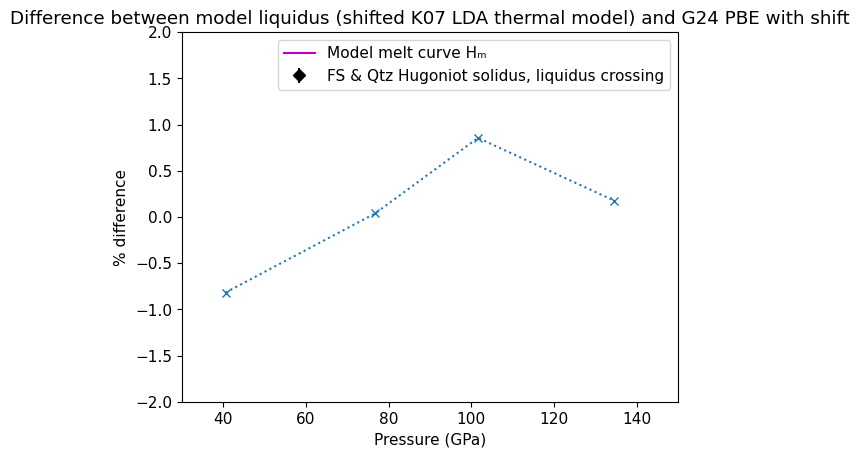

In [40]:
#plt.plot(eosdat_list[G24mclrho['id']].P_liquid,eosdat_list[G24mclrho['id']].rho_liquid+pbe_liquid_density_shift,'+:',color='red',label=G24mclrho['lab']+ ' shift')
rho_model = np.interp(eosdat_list[G24mclrho['id']].P_liquid,stsmcsmooth.P,stsmcsmooth.rho)
plt.plot(eosdat_list[G24mclrho['id']].P_liquid[0:4],(rho_model[0:4]/(eosdat_list[G24mclrho['id']].rho_liquid[0:4]+pbe_liquid_density_shift)-1)*100,'x:')
plt.ylim(-2,2)
plt.xlim(30,150)
plt.xlabel('Pressure (GPa)')
plt.ylabel('% difference')
plt.title('Difference between model liquidus (shifted K07 LDA thermal model) and G24 PBE with shift')
plt.show()

## Print the fiducial melt curve

This melt curve is stored in scripts/melt-curve.txt for use in all the other notebooks.

In [41]:
%%capture
##print(p1,p2)
# comment out %% capture for melt curve listing
pcheck=[]
tcheck=[]
print('P (GPa), T (K)')


for i in np.arange(1,5):
    print(i,', ',sio2_mc_staticqtz.calcf(i))
    pcheck.append(i)
    tcheck.append(sio2_mc_staticqtz.calcf(i))
for i in np.arange(5,13):
    print(i,', ',sio2_mc_staticlow.calcf(i))
    pcheck.append(i)
    tcheck.append(sio2_mc_staticlow.calcf(i))
xx=np.arange((p1-13))+13
for i in xx:
    print(i,', ', sio2_mc_static.a[0]+sio2_mc_static.a[1]*np.power(i,sio2_mc_static.a[2])) # fit from above
    pcheck.append(i)
    tcheck.append(sio2_mc_static.a[0]+sio2_mc_static.a[1]*np.power(i,sio2_mc_static.a[2]))
    

xx = np.arange(p2-np.round(p1))+np.round(p1)+1 # GPa
for i in xx:
    print(i,', ', 6.018*np.power((1+(i+202.338)/4.736e-04),0.5126)) # 2phase - confirmed with authors that this is correct 8/2025
    pcheck.append(i)
    tcheck.append(6.018*np.power((1+(i+202.338)/4.736e-04),0.5126))

# ADD 100 K to make the curve monotonically increasing
xx = np.arange(6000-np.round(p2))+np.round(p2)+1 # GPa
for i in xx:
    print(i,', ', sio2_mc_G16mod.a[0]+sio2_mc_G16mod.a[1]*np.power(i,sio2_mc_G16mod.a[2])) # fit from above with continuity shift
    pcheck.append(i)
    tcheck.append(sio2_mc_G16mod.a[0]+sio2_mc_G16mod.a[1]*np.power(i,sio2_mc_G16mod.a[2]))



In [42]:
print(p1,p2)

10.477441985176059 512.8369433815569


In [43]:
for i in np.arange(20):
    print(i,pcheck[i],stsmcsmooth.P[i],tcheck[i]-stsmcsmooth.T[i])

0 1 1.0 0.0
1 2 2.0 0.0
2 3 3.0 0.0
3 4 4.0 0.0
4 5 5.0 0.0
5 6 6.0 0.0
6 7 7.0 0.0
7 8 8.0 0.0
8 9 9.0 0.0
9 10 10.0 0.0
10 11 11.0 0.0
11 12 12.0 0.0
12 11.0 13.0 1600.3038465112986
13 12.0 14.0 1523.029734041097
14 13.0 15.0 1451.4573101694814
15 14.0 16.0 1384.869937384915
16 15.0 17.0 1322.6788531005022
17 16.0 18.0 1264.3943253956768
18 17.0 19.0 1209.6045284745778
19 18.0 20.0 1157.959780306005


In [44]:
plt.plot(stsmcsmooth.P,stsmcsmooth.T,'r-')
#    '''Simons function f(x) = a[0] + a[1]*x^a[2]'''
ppp = np.arange(.5,7,.1)
ttt = sio2_mc_staticqtz.calcf(ppp)
plt.plot(ppp,ttt,'r-',label='Lowest pressure simons fit - this work')
pppa=ppp
ttta=ttt
print('P at 1999K =',np.interp(1999,ttt,ppp))

ppp = np.arange(4,15,.1)
ttt = sio2_mc_cst.calcf(ppp)
pppb=ppp
tttb=ttt
plt.plot(ppp,ttt,'m-',label='Lowest pressure simons fit - this work')
#plt.plot(gm24mc.P,gm24mc.T,'-',color='c',label='G24 MC 2phase PBE')
#ppp0 = ppp
#ttt0 = ttt
plt.ylim(1900,3500)
plt.xlim(0,25)
ppp = np.arange(10,120,1)
ttt = sio2_mc_stv.calcf(ppp)
plt.plot(ppp,ttt,'m--',label='fit stv')

pppc=ppp
tttc=ttt

#print(ppp,ttt)
if 1:
    x1,y1=intersection(pppa,ttta,pppb,tttb)
    p1=x1[0]
    t1=y1[0]
    print('Intersection (P,T) = ',p1,t1)
    plt.plot(p1,t1,'mD',label='intersection point')

if 1:
    x1,y1=intersection(pppb,tttb,pppc,tttc)
    p1=x1[0]
    t1=y1[0]
    print('Intersection (P,T) = ',p1,t1)
    plt.plot(p1,t1,'mD',label='intersection point')
if 1:
    # DAC melt curve points
    # stv melt curve Shen and Lazer 1995
    plt.errorbar(eosdat_list[S95mcstv['id']].P,eosdat_list[S95mcstv['id']].T,\
                 xerr=eosdat_list[S95mcstv['id']].P_std,yerr=eosdat_list[S95mcstv['id']].T_std,\
                 fmt='d',color='wheat',mfc='grey',label=S95mcstv['lab'])
    # Andrault et al. 2022 revised
    plt.plot(eosdat_list[A22mc['id']].P,eosdat_list[A22mc['id']].T,'cd',mfc='grey',label=A22mc['lab'])
    plt.plot(13.7,2800+273,'kD',label='Zhang et al. 1993 TP')
    plt.plot(15,2900,'bD',label='Andrault et al. 2022 TP')
    plt.plot(14.5,3100,'rD',label='Belonoshko & Drubovinsky 1995 TP')

P at 1999K = 0.6750534282549683
Intersection (P,T) =  4.3794737788828995 2679.3902737616863
Intersection (P,T) =  10.477441985176059 2901.752586925874


In [45]:
def curve2num(curvetype):
    if curvetype == 'linear':
        return 1
    if curvetype == 'quadratic':
        return 2
    if curvetype == 'cubic':
        return 3
    if curvetype == 'fourthpoly':
        return 4
def myform(x):
    s = print('%12.6e' % x )
    return str(s)

def format_matrix(matrix, environment="bmatrix", formatter=lambda s: '%12.6e' % s):
    """Format a matrix using LaTeX syntax"""

    if not isinstance(matrix, np.ndarray):
        try:
            matrix = np.array(matrix)
        except Exception:
            raise TypeError("Could not convert to Numpy array")

    if len(shape := matrix.shape) == 1:
        matrix = matrix.reshape(1, shape[0])
    elif len(shape) > 2:
        raise ValueError("Array must be 2 dimensional")

    body_lines = [" & ".join(map(formatter, row)) for row in matrix]

    body = "\\\\\n".join(body_lines)
    return f"""\\begin{{{environment}}}
{body}
\\end{{{environment}}}"""

def tomatrix(fit,var,label):
    s1='% '+fit.filename+' \n'
    s2='\\label{'+label+'} \n'
    s3 = '\\Sigma'+var+' &=& '+format_matrix2(fit.cov) + ' \\\\'
    print(s1+s2+s3)

def fnum(a):
    s = ''
    if abs(a) < 100000 and abs(a) > 1.e-5:
        s += '%12.6f' % a
    else:
        s += '%12.6e' % a
    return s
def fnum2(a):
    return '%12.6e' % a

def xfrexp10(x):
    exp = int(np.floor(np.log10(abs(x))))
    if exp != 0:
        s = str(x / 10**exp)[0:8]+' \\times 10^{'+str(exp)+'}'
    else:
        s = str(x / 10**exp)[0:8]        
    return s
def frexp10(x):
    #if x != 0:
    #    exp = int(np.floor(np.log10(abs(x))))
    #if exp != 0:
    s = '\\textrm{'+fnum2(x)+'}'
    #else:
    #    s = str(x)[0:8]        
    return s    
#def format_matrix2(matrix, environment="bmatrix", \
#                   formatter=lambda s: '%12.6f' % s):
def format_matrix2(matrix, environment="bmatrix", \
                   formatter=frexp10):
        
    """Format a matrix using LaTeX syntax"""

    if not isinstance(matrix, np.ndarray):
        try:
            matrix = np.array(matrix)
        except Exception:
            raise TypeError("Could not convert to Numpy array")

    if len(shape := matrix.shape) == 1:
        matrix = matrix.reshape(1, shape[0])
    elif len(shape) > 2:
        raise ValueError("Array must be 2 dimensional")

    body_lines = [" & ".join(map(formatter, row)) for row in matrix]
#    body_lines = [" & ".join(str(row)) for row in matrix]

    body = "\\\\\n".join(body_lines)
    return f"""\\begin{{{environment}}}
{body}
\\end{{{environment}}}"""

def formata(a):
    s='['
    for i in range(len(a)):
        if max(abs(a)) < 100000 and min(abs(a)) > 1.e-5:
            s += '%12.6f' % a[i]
        else:
            s += '%12.6e' % a[i]
        if i < len(a)-1:
            s += ', '
        else:
            s += ']'
    return s

def formatstr(val,err,n):
    #print(val,err,n)
    #print(str(int(np.round(val*np.pow(10,n))))[-1:])
    if str(int(np.round(val*np.pow(10,n))))[-1:] == '0':
        sss=(str(np.round(val*np.pow(10,n))/np.pow(10,n))+'0 ± '+str(np.round(err*np.pow(10,n))/np.pow(10,n)))
    else:
        sss=(str(np.round(val*np.pow(10,n))/np.pow(10,n))+' ± '+str(np.round(err*np.pow(10,n))/np.pow(10,n)))
    if n == 0:
        sss=(str(int(np.round(val*np.pow(10,n))))+' ± '+str(int(np.round(err*np.pow(10,n)))))
        
    return sss


In [46]:
## print covariance matrices for paper appendix
tomatrix(sio2_mc_staticqtz,'_{T}','eq:mc_bqtz_cov')

% SiO2_fithighqtzstatic_simons 
\label{eq:mc_bqtz_cov} 
\Sigma_{T} &=& \begin{bmatrix}
\textrm{5.164081e+05} & \textrm{-6.519741e+05} & \textrm{2.468882e+05} & \textrm{-2.907986e+04}\\
\textrm{-6.519741e+05} & \textrm{8.585698e+05} & \textrm{-3.335649e+05} & \textrm{3.998159e+04}\\
\textrm{2.468882e+05} & \textrm{-3.335649e+05} & \textrm{1.319619e+05} & \textrm{-1.603256e+04}\\
\textrm{-2.907986e+04} & \textrm{3.998159e+04} & \textrm{-1.603256e+04} & \textrm{1.968596e+03}
\end{bmatrix} \\


In [47]:
tomatrix(sio2_mc_cst,'_{T}','eq:mc_cst_cov')

% SiO2_fitcoesitestatic_simons 
\label{eq:mc_cst_cov} 
\Sigma_{T} &=& \begin{bmatrix}
\textrm{3.273871e+04} & \textrm{-1.027838e+04} & \textrm{1.037159e+03} & \textrm{-3.386336e+01}\\
\textrm{-1.027838e+04} & \textrm{3.284896e+03} & \textrm{-3.361838e+02} & \textrm{1.110411e+01}\\
\textrm{1.037159e+03} & \textrm{-3.361838e+02} & \textrm{3.481006e+01} & \textrm{-1.161202e+00}\\
\textrm{-3.386336e+01} & \textrm{1.110411e+01} & \textrm{-1.161202e+00} & \textrm{3.907114e-02}
\end{bmatrix} \\


In [48]:
tomatrix(sio2_mc_stv,'_{T}','eq:mc_stv_cov')

% SiO2_fitstvstatic_simons 
\label{eq:mc_stv_cov} 
\Sigma_{T} &=& \begin{bmatrix}
\textrm{1.617653e+09} & \textrm{-1.580098e+09} & \textrm{5.621037e+03}\\
\textrm{-1.580098e+09} & \textrm{1.543443e+09} & \textrm{-5.491046e+03}\\
\textrm{5.621037e+03} & \textrm{-5.491046e+03} & \textrm{1.954174e-02}
\end{bmatrix} \\


In [49]:
tomatrix(sio2_mc_G16mod,'_{T}','eq:mc_g16mod_cov')

% SiO2_fitG16mod_simons 
\label{eq:mc_g16mod_cov} 
\Sigma_{T} &=& \begin{bmatrix}
\textrm{2.242432e+06} & \textrm{-1.055374e+06} & \textrm{2.842907e+01}\\
\textrm{-1.055374e+06} & \textrm{4.981449e+05} & \textrm{-1.344001e+01}\\
\textrm{2.842907e+01} & \textrm{-1.344001e+01} & \textrm{3.629615e-04}
\end{bmatrix} \\


## CHECK THAT MELT CURVE MATCHES melt-curve.txt